# TravelTide - Explorative Datenanalyse

## 1. Vorbereitung und Datenimport

### 1.1 Setup und Konfiguration
Die benötigten Bibliotheken und Einstellungen werden geladen. Der Ladebalken zeigt die Prüfung und gegebenenfalls Installation der Pakete; seine Schrittnummern gelten nur für das Setup.

**Rolle dieses Notebooks:** Exploration der ursprünglichen CSVs und Dokumentation der
Datenqualität. Der Datenbruch ab 21.07.2023 bleibt hier zur Diagnose sichtbar.
Die verbindliche Feature- und Segmentauswertung verwendet ab Notebook 02 den Stichtag
aus `config.ANALYSIS_REFERENCE_DATE`. Endergebnisse stehen in Notebook 05.

In [ ]:
# Standardbibliothek und Notebook-Anzeige
import csv
import importlib
import subprocess
import sys


import inspect
from html import escape
from pathlib import Path
from uuid import uuid4
from IPython.display import HTML, Markdown, display, update_display

# Weitere Pakete werden unten nach ihrer Verfuegbarkeitspruefung importiert.

# Zu prüfende Pakete: Importname → pip-Paketname
packages = {
    "pandas": "pandas",
    "psycopg2": "psycopg2-binary",
    "airports": "airports-py",
    "numpy": "numpy",
    "jinja2": "jinja2",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

TOTAL_STEPS = len(packages) + 1
PROGRESS_ID = f"setup_{uuid4().hex}"


def show_progress(message, step, completed):
    percent = round(100 * completed / TOTAL_STEPS)

    progress_html = (
        '<div style="margin:8px 0;">'
        f'<div style="margin-bottom:6px;">'
        f'<strong>Schritt {step} von {TOTAL_STEPS}</strong>'
        f' · {escape(message)}</div>'
        '<div style="display:flex;align-items:center;gap:12px;">'
        '<div style="flex:1;background:#dbe4ed;border-radius:6px;height:16px;">'
        f'<div style="width:{percent}%;background:#2196f3;height:16px;'
        'border-radius:6px;"></div></div>'
        f'<span style="min-width:48px;text-align:right;">{percent}%</span>'
        '</div></div>'
    )

    update_display(HTML(progress_html), display_id=PROGRESS_ID)


display(HTML("Setup wird gestartet …"), display_id=PROGRESS_ID)

try:
    # Schritt 1: Konfiguration laden
    show_progress("Konfiguration wird geladen …", step=1, completed=0)

    import config
    importlib.reload(config)

    DATABASE_URL = config.DATABASE_URL
    QUERIES = config.QUERIES
    PARAMS = config.PARAMS
    THEME = config.THEME
    PERK_COLORS = config.PERK_COLORS
    WIDTH = config.WIDTH


    show_progress("✓ Konfiguration geladen.", step=1, completed=1)

    # Weitere Schritte: Pakete prüfen und bei Bedarf installieren
    for step, (module_name, package_name) in enumerate(
        packages.items(), start=2
    ):
        show_progress(
            f"{package_name} wird geprüft …",
            step=step,
            completed=step - 1,
        )

        try:
            importlib.import_module(module_name)
            message = f"✓ {package_name} bereits verfügbar."

        except ImportError:
            show_progress(
                f"{package_name} wird installiert …",
                step=step,
                completed=step - 1,
            )

            subprocess.run(
                [
                    sys.executable,
                    "-m",
                    "pip",
                    "install",
                    "--quiet",
                    package_name,
                ],
                check=True,
                timeout=120,
            )

            importlib.invalidate_caches()
            importlib.import_module(module_name)
            message = f"✓ {package_name} installiert und geprüft."

        show_progress(message, step=step, completed=step)

    # Imports für die weitere Arbeit
    from matplotlib.ticker import FuncFormatter
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    import numpy as np
    import psycopg2
    from airports import airport_data
    import eda_functions as eda

    importlib.reload(eda)

    show_progress(
        "✓ Setup abgeschlossen.",
        step=TOTAL_STEPS,
        completed=TOTAL_STEPS,
    )

except Exception:
    show_progress(
        "✗ Setup fehlgeschlagen. Siehe Fehlermeldung unten.",
        step=step if "step" in locals() else 1,
        completed=0,
    )
    raise

# Gemeinsame Hilfsfunktionen - nur hier definiert
def show_export_status(name, message, path, skipped=False):
    background = (
        THEME["surface_alt"] if skipped else THEME["success_bg"]
    )
    border = (
        THEME["secondary"] if skipped else THEME["success_border"]
    )

    return f"""
    <div style="
        flex:0 0 300px;
        padding:12px 16px;
        background:{background};
        border-left:4px solid {border};
        border-radius:6px;
        box-sizing:border-box;
    ">
        <strong>{escape(name)}</strong>
        <div style="margin-top:6px;">{escape(message)}</div>
        <div style="
            margin-top:8px;
            font-size:12px;
            overflow-wrap:anywhere;
        ">
            {escape(str(path))}
        </div>
    </div>
    """

def update_export_display():
    export_display.update(HTML(
        '<div style="display:flex; gap:16px; overflow-x:auto;'
        'align-items:flex-start; padding:8px 0 12px;">'
        + "".join(status_cards)
        + "</div>"
    ))

def as_bool(series):
    values = series.astype("string").str.strip().str.lower()
    return values.map({"true": True, "false": False, "1": True, "0": False}).astype("boolean")

def numeric_summary(frame, columns):
    return frame[columns].describe(percentiles=[0.25, 0.5, 0.75]).T

def distribution(series):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({"Anzahl": counts, "Anteil (%)": counts / len(series) * 100})

def apply_text_change(frame, table_name, column, updated):
    before = frame[column].astype("string")
    updated = updated.astype("string")

    changed = (
        before.fillna("").ne(updated.fillna(""))
        | before.isna().ne(updated.isna())
    )

    if changed.any():
        detail = (
            pd.DataFrame({
                "Vorher": before.loc[changed],
                "Nachher": updated.loc[changed],
            })
            .groupby(["Vorher", "Nachher"], dropna=False)
            .size()
            .reset_index(name="Geänderte Zeilen")
        )

        detail.insert(0, "Spalte", column)
        detail.insert(0, "Tabelle", table_name)
        change_details.append(detail)

    # Änderung tatsächlich speichern
    frame[column] = updated

def format_duration(minutes):
    if pd.isna(minutes):
        return "-"

    seconds = round(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"

def show_note(text, warning=False):
    background = THEME["danger_bg"] if warning else THEME["surface_alt"]
    border = THEME["danger_border"] if warning else THEME["secondary"]

    display(HTML(f"""
    <div style="
        padding:12px 16px;
        margin:12px 0;
        background:{background};
        border-left:4px solid {border};
        border-radius:6px;
    ">
        {escape(text)}
    </div>
    """))

def finish_plot(fig):
    fig.tight_layout()
    plt.show()

# Einheitliches Theme für alle späteren Diagramme
# Diagrammgestaltung: einzige Farbquelle ist config.py.
def apply_config_plot_theme():
    plt.rcParams.update({
        "figure.facecolor": THEME["background"],
        "axes.facecolor": THEME["surface"],
        "savefig.facecolor": THEME["background"],
        "axes.titlecolor": THEME["primary"],
        "axes.titleweight": "bold",
        "axes.labelcolor": THEME["text"],
        "text.color": THEME["text"],
        "xtick.color": THEME["text_muted"],
        "ytick.color": THEME["text_muted"],
        "axes.edgecolor": THEME["border"],
        "grid.color": THEME["border"],
        "legend.facecolor": THEME["surface"],
        "legend.edgecolor": THEME["border"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.prop_cycle": plt.cycler(color=THEME["chart_colors"]),
    })
    # Negative / neutrale / positive Werte bleiben bei Korrelationen unterscheidbar.
    return plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        "traveltide_diverging",
        [THEME["danger_border"], THEME["surface"], THEME["primary"]],
    )

def perk_plot_color(label):
    mapping = {
        "Kostenlose Stornierung": "Free Cancellation",
        "Kostenloses Gepäck": "Free Baggage",
        "Kostenlose Mahlzeiten": "Complimentary Meals",
        "Erste Hotelnacht kostenlos": "First Night Free",
        "Exklusive Rabatte": "Member Discounts",
    }
    return PERK_COLORS.get(mapping.get(str(label), str(label)), THEME["text_muted"])

THEME_DIVERGING_CMAP = apply_config_plot_theme()

def draw_treemap(group, x, y, width, height):
    """Rechteckfläche proportional zur Nutzeranzahl aufteilen."""
    if group.empty:
        return

    if len(group) == 1:
        name = group.index[0]
        row = group.iloc[0]

        color = (
            color_map(norm(row["mean_trips"]))
            if pd.notna(row["mean_trips"])
            else THEME["border"]
        )

        rectangle = plt.Rectangle(
            (x, y),
            width,
            height,
            facecolor=color,
            edgecolor=THEME["surface"],
            linewidth=2,
        )
        treemap_ax.add_patch(rectangle)

        brightness = np.dot(color[:3], [0.299, 0.587, 0.114])
        text_color = (
            THEME["surface"]
            if brightness < 0.5
            else THEME["text"]
        )

        average = (
            f"{row['mean_trips']:.2f}"
            if pd.notna(row["mean_trips"])
            else "-"
        )

        # Kleine Kacheln kürzer beschriften
        if width * height < 0.025:
            label = f"{name}"
        else:
            label = (
                f"{name}\n"
                f"{int(row['users']):,} Nutzer\n"
                f"Ø {average} Reisen"
            )

        text = treemap_ax.text(
            x + width / 2,
            y + height / 2,
            label,
            ha="center",
            va="center",
            fontsize=8,
            color=text_color,
            clip_on=True,
        )
        text.set_clip_path(rectangle)
        return

    weights = group["users"].to_numpy()

    split = int(
        np.argmin(
            np.abs(
                np.cumsum(weights)[:-1] - weights.sum() / 2
            )
        )
    ) + 1

    first = group.iloc[:split]
    second = group.iloc[split:]
    fraction = first["users"].sum() / group["users"].sum()

    # Tatsächliche Form des Diagrammfelds berücksichtigen
    bounds = treemap_ax.get_window_extent()
    split_vertically = (
        width * bounds.width >= height * bounds.height
    )

    if split_vertically:
        first_width = width * fraction

        draw_treemap(first, x, y, first_width, height)
        draw_treemap(
            second,
            x + first_width,
            y,
            width - first_width,
            height,
        )
    else:
        first_height = height * fraction

        draw_treemap(first, x, y, width, first_height)
        draw_treemap(
            second,
            x,
            y + first_height,
            width,
            height - first_height,
        )



### 1.2 SQL-Daten abfragen und als CSV speichern
Die Abfragen aus `config.QUERIES` werden ausgeführt und im konfigurierten Datenordner gespeichert. Bereits vorhandene CSV-Dateien werden übersprungen und dadurch nicht automatisch aktualisiert.

In [ ]:
# Standardmäßig vorhandene CSVs verwenden. Nur bewusst für einen Neuabruf aktivieren.
RUN_DATABASE_EXPORT = False
if RUN_DATABASE_EXPORT:
    if not config.DATABASE_URL:
        raise ValueError("Für einen Datenbankabruf secrets.json konfigurieren.")
    status_cards = []
    
    # Einen Ausgabebereich erstellen, der laufend aktualisiert wird
    export_display = display(
        HTML("<p>Export wird gestartet …</p>"),
        display_id=True,
    )
    
    
    
    
    with psycopg2.connect(DATABASE_URL) as connection:
        with connection.cursor() as cursor:
            for name, query in QUERIES.items():
                csv_path = query["csv"]
    
                if csv_path.exists():
                    status_cards.append(
                        show_export_status(
                            name,
                            "✓ Datei bereits vorhanden - übersprungen.",
                            csv_path,
                            skipped=True,
                        )
                    )
                    update_export_display()
                    continue
    
                csv_path.parent.mkdir(parents=True, exist_ok=True)
    
                cursor.execute(query["sql"], PARAMS)
    
                with csv_path.open(
                    "w", newline="", encoding="utf-8"
                ) as file:
                    writer = csv.writer(file)
                    writer.writerow(
                        column[0] for column in cursor.description
                    )
                    writer.writerows(cursor)
    
                status_cards.append(
                    show_export_status(
                        name,
                        "✓ CSV-Datei gespeichert.",
                        csv_path,
                    )
                )
                update_export_display()
else:
    missing = [str(query["csv"]) for query in config.QUERIES.values() if not query["csv"].is_file()]
    if missing:
        raise FileNotFoundError("Quell-CSVs fehlen: " + ", ".join(missing))
    show_note("Vorhandene Quell-CSVs werden verwendet. Kein Datenbankabruf ausgeführt.")


### 1.3 CSV-Dateien als DataFrames laden
Die gespeicherten CSV-Dateien werden eingelesen. `df` enthält alle Tabellen als Dictionary; `df_sessions`, `df_flights`, `df_users` und `df_hotels` ermöglichen den direkten Zugriff.

**Voraussetzung:** Die Setup-Zelle muss zuerst ausgeführt werden; sie lädt auch `eda_functions` als `eda`.

In [3]:
df = eda.load_tables(config.QUERIES)

df_sessions = df["Sessions"]
df_flights = df["Flights"]
df_users = df["Users"]
df_hotels = df["Hotels"]

## 2. Tabellenvorschau und Datenqualität
Jede Tabelle wird einzeln betrachtet. Die Vorschau zeigt die ersten und letzten Zeilen; die Spaltenübersicht fasst fehlende Werte, eindeutige Werte, Min/Max und Inhaltstypen zusammen.

Die automatische Typprüfung erkennt Abweichungen vom häufigsten Inhaltstyp. Sie ersetzt keine Prüfung gegen fachlich festgelegte Solltypen. Wiederholte Werte und fehlende Buchungsangaben sind nicht automatisch Datenfehler.

### 2.1 Sessions
Die Session-Daten werden auf Struktur und Auffälligkeiten untersucht. Insbesondere sind Zeitangaben, Buchungsmerkmale und fehlende Angaben zu Reisen oder Buchungen zu betrachten.

In [4]:
display(HTML(f"""
<div style="
    padding:12px 16px;
    background:{THEME['surface_alt']};
    border-left:4px solid {THEME['secondary']};
    border-radius:6px;
">
    <strong>EDA-Funktionen neu geladen</strong>

    <p style="margin:8px 0;">
        Übernimmt gespeicherte Änderungen an <code>eda_functions.py</code>,
        ohne den Notebook-Kernel neu zu starten.
        Bestehende Ausgaben müssen anschließend erneut ausgeführt werden.
    </p>

    <div><strong>Geladene Datei:</strong>
        <code>{escape(str(eda.__file__))}</code>
    </div>

    <div style="margin-top:6px;">
        <strong>Funktionsparameter:</strong>
        <code>{escape(str(inspect.signature(eda.display_table)))}</code>
    </div>

    <p style="margin:8px 0 0;font-size:12px;">
        Dateipfad und Parameter helfen zu prüfen, ob die richtige Datei
        und die aktuelle Funktionsversion verwendet werden.
    </p>
</div>
"""))

In [5]:
eda.preview_tables(
    {"Sessions": df_sessions},
    config.THEME,
    n=5,
    card_width=WIDTH,
)

sessions_overview = eda.column_overview(df_sessions)

eda.display_table(
    sessions_overview,
    title="Sessions: Datenqualität",
    card_width=WIDTH,
)

,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,-,2023-01-04 19:30:00,2023-01-04 19:33:53,False,False,-,-,False,False,32,False
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,-,2023-01-04 19:49:00,2023-01-04 19:49:37,False,False,-,-,False,False,5,False
2,149058-6718f71e85ab413394e32abf5c49f978,149058,149058-0562d645484d450b8908ae40825aaf46,2023-01-04 13:30:00,2023-01-04 13:31:57,False,False,-,-,True,True,16,False
3,229108-d2b0f9bc7aea425189cb943fa1706810,229108,-,2023-01-04 20:44:00,2023-01-04 20:45:29,True,False,0.200000,-,False,False,12,False
4,264470-71e8f4d269aa44308aa34ffd1c2d0c18,264470,-,2023-01-04 22:50:00,2023-01-04 22:50:59,False,False,-,-,False,False,8,False
49206,589228-c82de5b13d8d4739aeb90e2ca924d2e0,589228,589228-7cbd8bd73eed4c549a0074919e71fdc8,2023-07-20 21:01:17,2023-07-20 21:45:04.905844,True,True,-,-,True,True,43,True
49207,671151-fa865fb0bf8249aeb164408b470322d2,671151,671151-a25acb9062764a168fbd4286d15d57fd,2023-07-24 17:45:47,2023-07-24 18:09:14.839854,True,True,-,-,True,True,23,True
49208,609393-17fa2042385e48faac6ab20586749340,609393,609393-b92d487037ec447db1e3ddf977709a52,2023-07-21 21:02:05,2023-07-21 21:27:18.179946,True,True,-,-,True,True,25,True
49209,562275-67b9889219d14b96b4cbdab763e094af,562275,562275-5b2550a902f14543a77ca64eccdce8f8,2023-07-21 21:17:07,2023-07-21 23:17:07,True,True,-,-,True,True,139,True
49210,591582-98ac1bd6d6824ad0b2831e9b93c50703,591582,591582-61f9e9bfb2dd461989dacc9f5b76371b,2023-07-21 10:24:10,2023-07-21 10:34:10,True,True,-,-,True,True,10,True


,Datentyp (pandas),Nicht fehlend,Fehlend,Fehlend (%),Eindeutige Werte,Min,Max,Häufigster Wert,Häufigster Wert (%),Häufigster Inhaltstyp,Typübereinstimmung (%),Typabweichungen,Ungültige Datumswerte,Leertexte,Status
Spalte,,,,,,,,,,,,,,,
session_id,str,49211,0,0.00,49211,-,-,23557-3f6bd6be250e45959b33b808ac525df6,0.00,Text,100.00,0,0,0,✅ Vollständig & einheitlich
user_id,int64,49211,0,0.00,5998,-,-,507513,0.02,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich
trip_id,str,16702,32509,66.06,16099,-,-,487715-e68df9b9798b40868247fa4331c93c3a,0.01,Text,100.00,0,0,0,⚠️Fehlende Werte
session_start,str,49211,0,0.00,42488,2023-01-04 00:01:00+00:00,2023-07-28 19:58:52+00:00,2023-02-24 21:07:00,0.01,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
session_end,str,49211,0,0.00,49060,2023-01-04 00:04:23+00:00,2023-07-28 20:08:52+00:00,2023-01-05 14:53:50,0.00,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
flight_discount,bool,49211,0,0.00,2,-,-,False,81.93,Boolean,100.00,0,0,0,✅ Vollständig & einheitlich
hotel_discount,bool,49211,0,0.00,2,-,-,False,86.15,Boolean,100.00,0,0,0,✅ Vollständig & einheitlich
flight_discount_amount,float64,8282,40929,83.17,12,0.050000,0.600000,0.1,32.07,Zahl,100.00,0,0,0,⚠️Fehlende Werte
hotel_discount_amount,float64,6205,43006,87.39,9,0.050000,0.450000,0.1,36.97,Zahl,100.00,0,0,0,⚠️Fehlende Werte


### 2.2 Flights
Die Flugdaten werden auf vorhandene Spalten, Wertebereiche und fehlende Angaben untersucht. Welche Informationen eine Zeile enthält, hängt von der zugrunde liegenden SQL-Abfrage ab.

In [7]:
eda.preview_tables({"flights": df_flights}, config.THEME, n=5, card_width=WIDTH,)

flights_overview = eda.column_overview(df_flights)
eda.display_table(flights_overview, title="Flights: Datenqualität", card_width=WIDTH,)

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
0,582979-5475b9940ee240bf9328a0cc0bc9900c,RNO,ottawa,YOW,1,True,2023-03-31 07:00:00,2023-04-07 07:00:00,1,Air Canada,45.323000,-75.669000,657.640000
1,514785-863ac3b4eb984f1eb226d67955623a5d,FTW,montreal,YHU,1,False,2023-06-21 15:00:00,-,0,Delta Air Lines,45.517000,-73.417000,221.830000
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,CLE,philadelphia,PHL,1,True,2023-04-04 08:00:00,2023-04-06 08:00:00,2,American Airlines,39.872000,-75.241000,106.000000
3,600395-79e934e3dcf2462587a0beffbebd6783,HOU,memphis,MEM,2,True,2023-04-21 13:00:00,2023-04-24 13:00:00,0,Delta Air Lines,35.042000,-89.977000,320.190000
4,474120-a87f749cf54b4f4ca9262d07080a06b2,YQB,san francisco,SFO,2,True,2023-02-02 07:00:00,2023-02-07 07:00:00,0,Alaska Airlines,37.619000,-122.375000,1507.830000
13712,512377-acf089357a6b497d91eda34bb532578d,LGA,washington,DCA,1,True,2023-04-02 10:00:00,2023-04-08 10:00:00,1,American Airlines,38.852000,-77.037000,59.340000
13713,510580-8e74d152377f43aeb23bbed9ff17deaa,PVD,montreal,YHU,1,True,2023-07-03 09:00:00,2023-07-06 09:00:00,1,Ryanair,45.517000,-73.417000,80.550000
13714,598533-40848e5db09e46aa8f56c0c3ccdefb2d,YYJ,macau,MFM,2,True,2024-01-23 19:00:00,2024-02-06 19:00:00,1,China Eastern Airlines,22.149000,113.591000,3861.040000
13715,497042-fa163de72e234eaf9c9bc8b477fbf66a,FAT,san antonio,RND,1,True,2023-04-13 07:00:00,2023-04-16 07:00:00,0,United Airlines,29.529000,-98.279000,369.100000
13716,610144-4e95defd2af24ea190dab8b1f563fd77,LAX,louisville,LOU,1,True,2023-07-05 12:00:00,2023-07-12 12:00:00,1,United Airlines,38.228000,-85.664000,508.950000


,Datentyp (pandas),Nicht fehlend,Fehlend,Fehlend (%),Eindeutige Werte,Min,Max,Häufigster Wert,Häufigster Wert (%),Häufigster Inhaltstyp,Typübereinstimmung (%),Typabweichungen,Ungültige Datumswerte,Leertexte,Status
Spalte,,,,,,,,,,,,,,,
trip_id,str,13717,0,0.00,13717,-,-,582979-5475b9940ee240bf9328a0cc0bc9900c,0.01,Text,100.00,0,0,0,✅ Vollständig & einheitlich
origin_airport,str,13717,0,0.00,159,-,-,LGA,6.31,Text,100.00,0,0,0,✅ Vollständig & einheitlich
destination,str,13717,0,0.00,125,-,-,new york,14.19,Text,100.00,0,0,0,✅ Vollständig & einheitlich
destination_airport,str,13717,0,0.00,183,-,-,JFK,7.20,Text,100.00,0,0,0,✅ Vollständig & einheitlich
seats,int64,13717,0,0.00,8,1,8,1,85.35,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich
return_flight_booked,bool,13717,0,0.00,2,-,-,True,95.65,Boolean,100.00,0,0,0,✅ Vollständig & einheitlich
departure_time,str,13717,0,0.00,2447,2023-01-07 07:00:00+00:00,2024-07-16 07:00:00+00:00,2023-02-12 07:00:00,0.38,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
return_time,str,13120,597,4.35,2460,2023-01-08 07:00:00+00:00,2024-07-30 16:00:00+00:00,2023-02-18 07:00:00,0.39,Datum,100.00,0,0,0,⚠️Fehlende Werte
checked_bags,int64,13717,0,0.00,8,0,8,0,48.73,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich


### 2.3 Users
Die Nutzerdaten werden auf Vollständigkeit und konsistente Inhalte geprüft. Auffälligkeiten bei IDs, Ortsangaben und gegebenenfalls Koordinaten werden für weitere Prüfungen festgehalten.

In [8]:
eda.preview_tables({"Users": df_users}, config.THEME, n=5, card_width=WIDTH,)

users_overview = eda.column_overview(df_users)
eda.display_table(users_overview, title="Users: Datenqualität", card_width=WIDTH,)

,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date
0,94883,1972-03-16,F,True,False,usa,kansas city,MCI,39.297000,-94.714000,2022-02-07
1,101486,1972-12-07,F,True,True,usa,tacoma,TCM,47.138000,-122.476000,2022-02-17
2,101961,1980-09-14,F,True,False,usa,boston,BOS,42.364000,-71.005000,2022-02-17
3,106907,1978-11-17,F,True,True,usa,miami,TNT,25.862000,-80.897000,2022-02-24
4,118043,1972-05-04,F,False,True,usa,los angeles,LAX,33.942000,-118.408000,2022-03-10
5993,780167,1974-06-08,F,True,True,usa,los angeles,LAX,33.942000,-118.408000,2023-04-25
5994,785186,1979-06-03,F,True,True,usa,little rock,LIT,34.729000,-92.224000,2023-04-27
5995,792549,1978-01-25,F,False,False,usa,kansas city,MCI,39.297000,-94.714000,2023-04-30
5996,811077,1979-02-22,F,True,True,usa,knoxville,TYS,35.812000,-83.993000,2023-05-06
5997,844489,2000-05-09,M,False,True,usa,el paso,BIF,31.849000,-106.380000,2023-05-18


,Datentyp (pandas),Nicht fehlend,Fehlend,Fehlend (%),Eindeutige Werte,Min,Max,Häufigster Wert,Häufigster Wert (%),Häufigster Inhaltstyp,Typübereinstimmung (%),Typabweichungen,Ungültige Datumswerte,Leertexte,Status
Spalte,,,,,,,,,,,,,,,
user_id,int64,5998,0,0.00,5998,-,-,94883,0.02,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich
birthdate,str,5998,0,0.00,4807,1935-05-10 00:00:00+00:00,2006-12-28 00:00:00+00:00,1986-07-11,0.08,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
gender,str,5998,0,0.00,3,-,-,F,88.23,Text,100.00,0,0,0,✅ Vollständig & einheitlich
married,bool,5998,0,0.00,2,-,-,False,55.95,Boolean,100.00,0,0,0,✅ Vollständig & einheitlich
has_children,bool,5998,0,0.00,2,-,-,False,67.36,Boolean,100.00,0,0,0,✅ Vollständig & einheitlich
home_country,str,5998,0,0.00,2,-,-,usa,83.21,Text,100.00,0,0,0,✅ Vollständig & einheitlich
home_city,str,5998,0,0.00,105,-,-,new york,11.34,Text,100.00,0,0,0,✅ Vollständig & einheitlich
home_airport,str,5998,0,0.00,159,-,-,LGA,6.04,Text,100.00,0,0,0,✅ Vollständig & einheitlich
home_airport_lat,float64,5998,0,0.00,158,21.316000,61.251000,40.777,6.04,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich


### 2.4 Hotels
Die Hoteldaten werden auf Struktur, fehlende Werte und auffällige Inhalte geprüft. Gleiche Hotelnamen können zu unterschiedlichen Reisen gehören und sind allein kein Duplikatnachweis.

In [9]:
eda.preview_tables({"Hotels": df_hotels}, config.THEME, n=5, card_width=WIDTH,)

hotels_overview = eda.column_overview(df_hotels)
eda.display_table(hotels_overview, title="Hotels: Datenqualität", card_width=WIDTH,)

,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd
0,582979-5475b9940ee240bf9328a0cc0bc9900c,NH Hotel - ottawa,6,1,2023-03-31 13:32:21.030000,2023-04-07 11:00:00,110
1,514785-863ac3b4eb984f1eb226d67955623a5d,Choice Hotels - montreal,3,1,2023-06-21 20:06:24.300000,2023-06-25 11:00:00,87
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,Accor - philadelphia,1,1,2023-04-04 10:43:44.175000,2023-04-05 11:00:00,126
3,600395-79e934e3dcf2462587a0beffbebd6783,Marriott - memphis,1,2,2023-04-21 15:58:28.200000,2023-04-23 11:00:00,153
4,474120-a87f749cf54b4f4ca9262d07080a06b2,Accor - san francisco,4,2,2023-02-02 14:18:11.205000,2023-02-07 11:00:00,346
14308,512377-acf089357a6b497d91eda34bb532578d,Marriott - washington,5,1,2023-04-02 12:25:51.465000,2023-04-08 11:00:00,446
14309,510580-8e74d152377f43aeb23bbed9ff17deaa,Crowne Plaza - montreal,1,1,2023-07-03 11:33:49.905000,2023-07-04 11:00:00,69
14310,598533-40848e5db09e46aa8f56c0c3ccdefb2d,Hyatt - macau,12,1,2024-01-24 09:54:31.635000,2024-02-05 11:00:00,114
14311,497042-fa163de72e234eaf9c9bc8b477fbf66a,Hyatt - san antonio,2,1,2023-04-13 11:40:58.350000,2023-04-15 11:00:00,103
14312,610144-4e95defd2af24ea190dab8b1f563fd77,Four Seasons - louisville,5,1,2023-07-05 17:42:22.545000,2023-07-11 11:00:00,341


,Datentyp (pandas),Nicht fehlend,Fehlend,Fehlend (%),Eindeutige Werte,Min,Max,Häufigster Wert,Häufigster Wert (%),Häufigster Inhaltstyp,Typübereinstimmung (%),Typabweichungen,Ungültige Datumswerte,Leertexte,Status
Spalte,,,,,,,,,,,,,,,
trip_id,str,14313,0,0.00,14313,-,-,582979-5475b9940ee240bf9328a0cc0bc9900c,0.01,Text,100.00,0,0,0,✅ Vollständig & einheitlich
hotel_name,str,14313,0,0.00,957,-,-,Conrad - new york,0.85,Text,100.00,0,0,0,✅ Vollständig & einheitlich
nights,int64,14313,0,0.00,41,-2,43,1,21.88,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich
rooms,int64,14313,0,0.00,4,1,4,1,84.52,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich
check_in_time,str,14313,0,0.00,12074,2023-01-05 11:00:00+00:00,2024-07-17 00:33:41.625000+00:00,2023-02-21 11:00:00,0.21,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
check_out_time,str,14313,0,0.00,371,2023-01-08 11:00:00+00:00,2024-07-29 11:00:00+00:00,2023-02-26 11:00:00,0.93,Datum,100.00,0,0,0,✅ Vollständig & einheitlich
hotel_per_room_usd,int64,14313,0,0.00,683,17,1376,91,0.70,Zahl,100.00,0,0,0,✅ Vollständig & einheitlich


## 3. Duplikate und Schlüsselbeziehungen prüfen
Alle Spalten einer Tabelle werden gemeinsam verglichen. Wiederholte Einzelwerte sind
nicht automatisch doppelte Datensätze. Die Detailansicht zeigt nur tatsächlich gefundene Zeilen.
Es werden keine Daten gelöscht.

In [11]:
duplicate_results = {}
duplicate_reports = {}

for name, frame in df.items():
    report, rows = eda.check_duplicates(frame)

    duplicate_reports[name] = report
    duplicate_results[name] = rows

    # 1. Bericht für diese Tabelle
    eda.display_table(
        report,
        title=f"{name}: Prüfung auf vollständig identische Zeilen",
        max_height=350,
        card_width=WIDTH,
    )

    # 2. Bemerkung direkt darunter
    if rows.empty:
        show_note(
            f"✓ {name}: Keine vollständig identischen Zeilen gefunden."
        )
    else:
        extra_duplicates = int(frame.duplicated().sum())

        show_note(
            f"{name}: {len(rows):,} Zeilen gehören zu Duplikatgruppen. "
            f"Davon sind {extra_duplicates:,} zusätzliche Wiederholungen "
            "nach dem ersten Auftreten. Es wurden keine Zeilen entfernt.",
            warning=True,
        )

        eda.display_table(
            rows,
            title=f"{name}: Betroffene Zeilen",
            max_height=350,
            card_width=WIDTH,
        )

,Zeilen,Zeilen in Duplikatgruppen,Wiederholungen nach erstem Auftreten
0,49211,0,0


,Zeilen,Zeilen in Duplikatgruppen,Wiederholungen nach erstem Auftreten
0,13717,0,0


,Zeilen,Zeilen in Duplikatgruppen,Wiederholungen nach erstem Auftreten
0,5998,0,0


,Zeilen,Zeilen in Duplikatgruppen,Wiederholungen nach erstem Auftreten
0,14313,0,0


### 3.1. Prüfung ob `user_id` das Präfix von `session_id` & `trip_id` ist

In [ ]:
id_check = df_sessions[[
    "session_id", "trip_id", "user_id"
]].copy()

# Präfixe als nullable String-Spalten speichern
for column in ["session_id", "trip_id"]:
    id_check[f"{column}_prefix"] = (
        id_check[column]
        .astype("string")
        .str.split("-", n=1)
        .str[0]
        .astype("string")
    )

user_id = id_check["user_id"].astype("string")

# Fehlende Werte bleiben als <NA> erhalten
id_check["Session passt zu User"] = (
    id_check["session_id_prefix"] == user_id
)
id_check["Trip passt zu User"] = (
    id_check["trip_id_prefix"] == user_id
)
id_check["Session- und Trip-Präfix gleich"] = (
    id_check["session_id_prefix"] == id_check["trip_id_prefix"]
)

eda.display_table(
    id_check.head(50),
    title="ID-Vergleich: erste 50 Zeilen - Zusammenfassung über alle Sessions",
    card_width=WIDTH,
    max_height=450,
)

# Zusammenfassung
id_check_summary = []

for column in [
    "Session passt zu User",
    "Trip passt zu User",
    "Session- und Trip-Präfix gleich",
]:
    result = id_check[column]

    id_check_summary.append({
        "Prüfung": column,
        "Übereinstimmung": int(result.fillna(False).sum()),
        "Abweichung": int((~result).fillna(False).sum()),
        "Nicht prüfbar": int(result.isna().sum()),
    })

eda.display_table(
    pd.DataFrame(id_check_summary).set_index("Prüfung"),
    title="ID-Präfixe: Zusammenfassung",
    card_width=WIDTH,
)

,session_id,trip_id,user_id,session_id_prefix,trip_id_prefix,Session passt zu User,Trip passt zu User,Session- und Trip-Präfix gleich
0,23557-3f6bd6be250e45959b33b808ac525df6,-,23557,23557,-,True,-,-
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,-,120851,120851,-,True,-,-
2,149058-6718f71e85ab413394e32abf5c49f978,149058-0562d645484d450b8908ae40825aaf46,149058,149058,149058,True,True,True
3,229108-d2b0f9bc7aea425189cb943fa1706810,-,229108,229108,-,True,-,-
4,264470-71e8f4d269aa44308aa34ffd1c2d0c18,-,264470,264470,-,True,-,-
5,348863-e3c9ba813fc84210a236a3a11e364859,-,348863,348863,-,True,-,-
6,349132-14d7bf94bf9b4f968d5fe6dad41ecced,349132-e1efc771d650473cafce78596f667408,349132,349132,349132,True,True,True
7,365825-7b348567fdae44498d5e8a0f0a5b1713,-,365825,365825,-,True,-,-
8,380874-05339fd92d834720802cfe6ea11f8fca,380874-1f29a1cd5b964153ab337c08a4c5a151,380874,380874,380874,True,True,True
9,385689-5a95f307608c4b5ab0d664fe6e9413b4,-,385689,385689,-,True,-,-


,Übereinstimmung,Abweichung,Nicht prüfbar
Prüfung,,,
Session passt zu User,49211,0,0
Trip passt zu User,16702,0,32509
Session- und Trip-Präfix gleich,16702,0,32509


## 4. Datenaufbereitung und Analysegrundlagen
Hier werden Datentypen vorbereitet und Qualitätsprüfungen durchgeführt. Die Rohdaten bleiben unverändert.

### 4.1. Analysekopien, Referenzdatum und Schlüssel

Die vorgegebenen SQL-Abfragen und Zeiträume bleiben unverändert. Für jede
Tabelle wird einmal eine Analysekopie erstellt; die Rohdaten bleiben erhalten.
Alle weiteren Berechnungen erfolgen auf diesen Kopien.

Als Referenzdatum für Alter und Kundendauer dient das letzte gültige
Session-Ende. Die Zeitstempel werden mit `format="mixed"` eingelesen und
einheitlich als UTC dargestellt. Ungültige Angaben werden durch
`errors="coerce"` zu `NaT` und separat geprüft.

Zusätzlich werden die Schlüssel `session_id`, `trip_id` beziehungsweise
`user_id` auf fehlende Werte und Eindeutigkeit geprüft.

In [13]:
# Kopie der DataFrames für die weitere Analyse:
sessions_analysis = df_sessions.copy()
flights_analysis = df_flights.copy()
users_analysis = df_users.copy()
hotels_analysis = df_hotels.copy()

In [14]:
# Hilfsfunktionen für gültige Kennzahlen und nullable Boolean-Werte
for frame, columns in [
    (sessions_analysis, ["session_start", "session_end"]),
    (flights_analysis, ["departure_time", "return_time"]),
    (users_analysis, ["birthdate", "sign_up_date"]),
    (hotels_analysis, ["check_in_time", "check_out_time"]),
]:
    for column in columns:
        frame[column] = pd.to_datetime(frame[column], errors="coerce", utc=True, format="mixed")

reference_date = sessions_analysis["session_end"].max()
if pd.isna(reference_date):
    raise ValueError("Kein gültiges Session-Ende für das Referenzdatum vorhanden.")

for frame, columns in [
    (sessions_analysis, ["flight_booked", "hotel_booked", "flight_discount", "hotel_discount", "cancellation"]),
    (flights_analysis, ["return_flight_booked"]),
    (users_analysis, ["married", "has_children"]),
]:
    for column in columns:
        frame[column] = as_bool(frame[column])

# Mehrdeutige Beziehungen nicht stillschweigend zusammenführen.
for name, frame, key in [
    ("Sessions", sessions_analysis, "session_id"),
    ("Flights", flights_analysis, "trip_id"),
    ("Hotels", hotels_analysis, "trip_id"),
    ("Users", users_analysis, "user_id"),
]:
    if frame[key].isna().any() or frame[key].duplicated().any():
        raise ValueError(f"{name}: {key} fehlt oder ist nicht eindeutig; vor Analyse prüfen.")

display(HTML(f"""
<div style="
    padding:12px 16px;
    background:{THEME['success_bg']};
    border-left:4px solid {THEME['success_border']};
    border-radius:6px;
">
    <strong>✓ Referenzdatum und Schlüsselprüfung abgeschlossen</strong>

    <p style="margin:8px 0;">
        <strong>Referenzdatum:</strong>
        {escape(reference_date.strftime('%d.%m.%Y %H:%M:%S UTC'))}
    </p>

    <div>
        Das letzte gültige Session-Ende dient als gemeinsamer Stichtag
        für Alter und Kundendauer.
    </div>

    <div style="margin-top:8px;">
        Alle geprüften Schlüssel sind vorhanden und innerhalb ihrer
        jeweiligen Tabelle eindeutig.
    </div>
</div>
"""))

conversion_quality = []
for name, raw, analysis, columns in [
    ("Sessions", df_sessions, sessions_analysis, ["session_start", "session_end"]),
    ("Flights", df_flights, flights_analysis, ["departure_time", "return_time"]),
    ("Users", df_users, users_analysis, ["birthdate", "sign_up_date"]),
    ("Hotels", df_hotels, hotels_analysis, ["check_in_time", "check_out_time"]),
]:
    for column in columns:
        conversion_quality.append({"Tabelle":name,"Spalte":column,
            "Ursprünglich fehlend":int(raw[column].isna().sum()),
            "Bei Konvertierung ungültig":int((raw[column].notna() & analysis[column].isna()).sum())})
eda.display_table(pd.DataFrame(conversion_quality), title="Datumsumwandlung", card_width=WIDTH)

,Tabelle,Spalte,Ursprünglich fehlend,Bei Konvertierung ungültig
0,Sessions,session_start,0,0
1,Sessions,session_end,0,0
2,Flights,departure_time,0,0
3,Flights,return_time,597,0
4,Users,birthdate,0,0
5,Users,sign_up_date,0,0
6,Hotels,check_in_time,0,0
7,Hotels,check_out_time,0,0


### 4.2 Schreibweise ausgewählter Textspalten prüfen

| Tabelle | Spalten |
|---|---|
| Sessions | Keine entsprechenden Textspalten |
| Flights | `destination` |
| Users | `home_city`; `home_country` separat |
| Hotels | `hotel_name` |

`.str.title()` kann Städtenamen vereinheitlichen, verändert aber auch
Abkürzungen und Eigennamen.<br>
Hotelnamen daher vor einer automatischen Umwandlung prüfen, beispielsweise „NH Hotel“ statt „Nh Hotel“.

Flughafencodes behalten ihre Großschreibung.

`home_country` wird anhand der vorhandenen Werte gezielt auf `USA` und
`Canada` vereinheitlicht.
>`.str.title()` würde aus `USA` fälschlich `Usa` machen.

#### **Prüfung** der Hotel Schreibweisen auf Eigennamen

In [15]:
hotel_examples = (
    hotels_analysis[["hotel_name"]]
    .dropna()
    .assign(
        hotel_brand=lambda frame: (
            frame["hotel_name"]
            .astype("string")
            .str.split(" - ", n=1)
            .str[0]
            .str.strip()
        )
    )
    .drop_duplicates(subset="hotel_brand")
    .sort_values("hotel_brand")
    .head(50)
    [["hotel_brand", "hotel_name"]]
    .reset_index(drop=True)
)

eda.display_table(
    hotel_examples,
    title="Eindeutige Hotelmarken mit Beispielnamen",
    card_width=WIDTH,
    max_height=450,
)

,hotel_brand,hotel_name
0,Accor,Accor - philadelphia
1,Aman Resorts,Aman Resorts - calgary
2,Banyan Tree,Banyan Tree - philadelphia
3,Best Western,Best Western - los angeles
4,Choice Hotels,Choice Hotels - montreal
5,Conrad,Conrad - charlotte
6,Crowne Plaza,Crowne Plaza - boston
7,Extended Stay,Extended Stay - baltimore
8,Fairmont,Fairmont - montreal
9,Four Seasons,Four Seasons - san antonio


> **Schreibweise der Hotelnamen:** Alle geprüften Hotelnamen enthalten das
Trennzeichen `" - "` zwischen Hotelkette und Stadt.
<br>Nur die Schreibweise
der Stadt wird vereinheitlicht. Markennamen wie **Shangri-La** und
**NH Hotel** bleiben unverändert.

## 5. Analyseplan und Spaltenerstellung

### 5.1. Sessions - Nutzungsverhalten und Buchungen

- **Sessiondauer:** Wie lange dauern Sessions im Durchschnitt? Wie unterscheiden sich Sessions mit und ohne Buchung?
- **Seitenaufrufe:** Wie viele Pageclicks haben Sessions mit vorhandener `trip_id` im Durchschnitt? Unterscheiden sie sich von Sessions ohne Reisezuordnung?
- **Rabatte:** Wie häufig werden Flug- und Hotelrabatte angeboten und wie hoch fallen sie aus? Besteht ein Zusammenhang mit der Buchungsquote?
- **Buchungskombinationen:** Wie verteilen sich die Sessions auf Flug und Hotel, nur Flug, nur Hotel sowie keine Buchung?
- **Stornierungen:** Welcher Anteil der gebuchten Reisen wird storniert?

In [16]:
s = sessions_analysis

# Sessiondauer numerisch für Berechnungen behalten
start = s["session_start"]
end = s["session_end"]

duration = (end - start).dt.total_seconds() / 60
s["valid_duration_min"] = duration.where(duration.ge(0))

# Reisezuordnung
s["has_trip"] = (s["trip_id"].notna() & s["trip_id"].astype("string").str.strip().ne("")).fillna(False)



flight = s["flight_booked"]
hotel = s["hotel_booked"]

s["any_booking"] = flight | hotel

# Buchungskombination
known = flight.notna() & hotel.notna()
flight_mask = flight.fillna(False)
hotel_mask = hotel.fillna(False)

s["booking_type"] = "Unbekannt"
s.loc[known & flight_mask & hotel_mask, "booking_type"] = "Flug und Hotel"
s.loc[known & flight_mask & ~hotel_mask, "booking_type"] = "Nur Flug"
s.loc[known & ~flight_mask & hotel_mask, "booking_type"] = "Nur Hotel"
s.loc[known & ~flight_mask & ~hotel_mask, "booking_type"] = "Keine Buchung"

# Stornomerkmal und Sessionmonat

s["session_month"] = start.dt.strftime("%Y-%m")

# Anzeigekopie: Dauer als Minuten:Sekunden
sessions_display = sessions_analysis.copy()

sessions_display["valid_duration_min"] = (
    sessions_analysis["valid_duration_min"].map(
        lambda value: (
            f"{round(value * 60) // 60}:{round(value * 60) % 60:02d}"
            if pd.notna(value)
            else "-"
        )
    )
)

sessions_display = sessions_display.rename(
    columns={"valid_duration_min": "Sessiondauer (Min:Sek)"}
)

eda.preview_tables(
    {"Sessions - Analyse": sessions_display},
    config.THEME,
    n=5,
    card_width=WIDTH,
)

,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,Sessiondauer (Min:Sek),has_trip,any_booking,booking_type,session_month
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,-,2023-01-04 19:30:00+00:00,2023-01-04 19:33:53+00:00,False,False,-,-,False,False,32,False,3:53,False,False,Keine Buchung,2023-01
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,-,2023-01-04 19:49:00+00:00,2023-01-04 19:49:37+00:00,False,False,-,-,False,False,5,False,0:37,False,False,Keine Buchung,2023-01
2,149058-6718f71e85ab413394e32abf5c49f978,149058,149058-0562d645484d450b8908ae40825aaf46,2023-01-04 13:30:00+00:00,2023-01-04 13:31:57+00:00,False,False,-,-,True,True,16,False,1:57,True,True,Flug und Hotel,2023-01
3,229108-d2b0f9bc7aea425189cb943fa1706810,229108,-,2023-01-04 20:44:00+00:00,2023-01-04 20:45:29+00:00,True,False,0.200000,-,False,False,12,False,1:29,False,False,Keine Buchung,2023-01
4,264470-71e8f4d269aa44308aa34ffd1c2d0c18,264470,-,2023-01-04 22:50:00+00:00,2023-01-04 22:50:59+00:00,False,False,-,-,False,False,8,False,0:59,False,False,Keine Buchung,2023-01
49206,589228-c82de5b13d8d4739aeb90e2ca924d2e0,589228,589228-7cbd8bd73eed4c549a0074919e71fdc8,2023-07-20 21:01:17+00:00,2023-07-20 21:45:04.905844+00:00,True,True,-,-,True,True,43,True,43:48,True,True,Flug und Hotel,2023-07
49207,671151-fa865fb0bf8249aeb164408b470322d2,671151,671151-a25acb9062764a168fbd4286d15d57fd,2023-07-24 17:45:47+00:00,2023-07-24 18:09:14.839854+00:00,True,True,-,-,True,True,23,True,23:28,True,True,Flug und Hotel,2023-07
49208,609393-17fa2042385e48faac6ab20586749340,609393,609393-b92d487037ec447db1e3ddf977709a52,2023-07-21 21:02:05+00:00,2023-07-21 21:27:18.179946+00:00,True,True,-,-,True,True,25,True,25:13,True,True,Flug und Hotel,2023-07
49209,562275-67b9889219d14b96b4cbdab763e094af,562275,562275-5b2550a902f14543a77ca64eccdce8f8,2023-07-21 21:17:07+00:00,2023-07-21 23:17:07+00:00,True,True,-,-,True,True,139,True,120:00,True,True,Flug und Hotel,2023-07
49210,591582-98ac1bd6d6824ad0b2831e9b93c50703,591582,591582-61f9e9bfb2dd461989dacc9f5b76371b,2023-07-21 10:24:10+00:00,2023-07-21 10:34:10+00:00,True,True,-,-,True,True,10,True,10:00,True,True,Flug und Hotel,2023-07


### 5.2. Flights - Reiseumfang und Flugkosten

>**Preisdefinition prüfen:** Bezeichnet `base_fare_usd` den Preis pro Sitzplatz oder den Gesamtpreis der Buchung?
>
> Dafür vergleichen wir die Preise nach Sitzplatzanzahl, möglichst innerhalb gleicher Strecken und getrennt nach Rückflugbuchung.<br>
> Die bisherige Verteilung spricht für einen Gesamtpreis vor Rabatt; diese Interpretation bleibt vorläufig.

- **Rückflug:** Wie häufig wird ein Hin- und Rückflug gebucht?
- **Sitzplätze:** Wie viele Sitzplätze werden pro Flugbuchung reserviert?
- **Gepäck:** Wie viele aufgegebene Gepäckstücke werden pro Buchung und pro Sitzplatz gebucht?
- **Flugpreis:** Wie verteilen sich die Basispreise? Wie hoch sind Durchschnitt, Median und Preis pro Sitzplatz?

In [17]:
# Preisdefinition prüfen:
fare_check = (
    flights_analysis.groupby("seats")["base_fare_usd"]
    .agg(
        bookings="count",
        mean_fare="mean",
        median_fare="median",
    )
)

eda.display_table(
    fare_check,
    title="Basispreis nach Anzahl gebuchter Sitzplätze",
)

,bookings,mean_fare,median_fare
seats,,,
1,11707,372.830677,349.820000
2,1480,981.256811,719.615000
3,378,1215.603915,984.535000
4,119,1911.345126,1396.100000
5,19,5737.085789,4417.600000
6,11,6825.070000,5248.990000
7,1,8431.340000,8431.340000
8,2,17241.550000,17241.550000


> **Preisinterpretation:** `base_fare_usd` wird vorläufig als Gesamtpreis der Flugbuchung vor Rabatt interpretiert.<br>
Bei ein bis vier Sitzplätzen liegt der Median pro Sitzplatz ähnlich bei etwa 328-360 USD. Buchungen mit mehr Sitzplätzen sind selten und weniger aussagekräftig.

In [18]:
seats = pd.to_numeric(
    flights_analysis["seats"], errors="coerce"
)
valid_seats = seats.where(seats.gt(0) & seats.mod(1).eq(0))

flights_analysis["bags_per_seat"] = (
    flights_analysis["checked_bags"] / valid_seats
)

# Vorläufig: base_fare_usd als Gesamtpreis vor Rabatt interpretiert
flights_analysis["fare_per_seat_usd"] = (
    flights_analysis["base_fare_usd"] / valid_seats
)

eda.preview_tables(
    {"Flights - Analyse": flights_analysis},
    config.THEME,
    n=5,
    card_width=WIDTH,
)

,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,bags_per_seat,fare_per_seat_usd
0,582979-5475b9940ee240bf9328a0cc0bc9900c,RNO,ottawa,YOW,1,True,2023-03-31 07:00:00+00:00,2023-04-07 07:00:00+00:00,1,Air Canada,45.323000,-75.669000,657.640000,1.000000,657.640000
1,514785-863ac3b4eb984f1eb226d67955623a5d,FTW,montreal,YHU,1,False,2023-06-21 15:00:00+00:00,-,0,Delta Air Lines,45.517000,-73.417000,221.830000,0.000000,221.830000
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,CLE,philadelphia,PHL,1,True,2023-04-04 08:00:00+00:00,2023-04-06 08:00:00+00:00,2,American Airlines,39.872000,-75.241000,106.000000,2.000000,106.000000
3,600395-79e934e3dcf2462587a0beffbebd6783,HOU,memphis,MEM,2,True,2023-04-21 13:00:00+00:00,2023-04-24 13:00:00+00:00,0,Delta Air Lines,35.042000,-89.977000,320.190000,0.000000,160.095000
4,474120-a87f749cf54b4f4ca9262d07080a06b2,YQB,san francisco,SFO,2,True,2023-02-02 07:00:00+00:00,2023-02-07 07:00:00+00:00,0,Alaska Airlines,37.619000,-122.375000,1507.830000,0.000000,753.915000
13712,512377-acf089357a6b497d91eda34bb532578d,LGA,washington,DCA,1,True,2023-04-02 10:00:00+00:00,2023-04-08 10:00:00+00:00,1,American Airlines,38.852000,-77.037000,59.340000,1.000000,59.340000
13713,510580-8e74d152377f43aeb23bbed9ff17deaa,PVD,montreal,YHU,1,True,2023-07-03 09:00:00+00:00,2023-07-06 09:00:00+00:00,1,Ryanair,45.517000,-73.417000,80.550000,1.000000,80.550000
13714,598533-40848e5db09e46aa8f56c0c3ccdefb2d,YYJ,macau,MFM,2,True,2024-01-23 19:00:00+00:00,2024-02-06 19:00:00+00:00,1,China Eastern Airlines,22.149000,113.591000,3861.040000,0.500000,1930.520000
13715,497042-fa163de72e234eaf9c9bc8b477fbf66a,FAT,san antonio,RND,1,True,2023-04-13 07:00:00+00:00,2023-04-16 07:00:00+00:00,0,United Airlines,29.529000,-98.279000,369.100000,0.000000,369.100000
13716,610144-4e95defd2af24ea190dab8b1f563fd77,LAX,louisville,LOU,1,True,2023-07-05 12:00:00+00:00,2023-07-12 12:00:00+00:00,1,United Airlines,38.228000,-85.664000,508.950000,1.000000,508.950000


### 5.3. Users - Kundenstruktur und Reiseaktivität

- **Demografie:** Wie verteilen sich Geschlecht, Familienstand und Haushalte mit Kindern?
- **Alter:** Wie sieht die Altersverteilung aus und welche Altersgruppen sind besonders aktiv?
    -   **Altersgruppen:** Die Gruppen 18-20 und 21-24 werden getrennt betrachtet,
    um mögliche Unterschiede im Reise- und Buchungsverhalten jüngerer Nutzer
    sichtbar zu machen. Dieselben Gruppen ermöglichen den Vergleich zwischen
    USA und Kanada. Die Einteilung beschreibt keine gesetzlichen Altersgrenzen.
    -   **Jahrgang** aus Geburtstag extrahieren.
- **Kundendauer:** Wie lange sind die Nutzer zum festgelegten Referenzdatum bereits registriert?
- **Reisehistorie:** Wann fand die erste beziehungsweise letzte Reise statt? Wie viele unterschiedliche Reisen hat jeder Nutzer insgesamt gebucht?

In [19]:
# Alter in vollendeten Jahren
birthdate = users_analysis["birthdate"]

birthday_pending = (
    (birthdate.dt.month > reference_date.month)
    | (
        birthdate.dt.month.eq(reference_date.month)
        & birthdate.dt.day.gt(reference_date.day)
    )
)

users_analysis["age_years"] = (
    reference_date.year
    - birthdate.dt.year
    - birthday_pending.astype(int)
).where(birthdate.le(reference_date))

users_analysis["age_group"] = pd.cut(
    users_analysis["age_years"],
    bins=[0, 18, 21, 25, 35, 45, 55, 65, np.inf],
    labels=[
        "Unter 18",
        "18-20",
        "21-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65+",
    ],
    right=False,
)

users_analysis["birth_year"] = birthdate.dt.year.where(birthdate.le(reference_date)) 

# Kundendauer in Tagen
signup = users_analysis["sign_up_date"]

users_analysis["customer_tenure_days"] = (
    reference_date.normalize() - signup.dt.normalize()
).dt.days.where(signup.le(reference_date))


# Reisehistorie wird nach der Hotelprüfung zentral in 5.6 ergänzt.

### 5.4. Hotels - Aufenthaltsdauer, Zimmer und Kosten
**Negative Nächte sind fachlich auffällig**, auch wenn der Inhaltstyp korrekt ist.

- **Aufenthaltsdauer prüfen:** Stimmt die angegebene Anzahl der Nächte mit der Differenz zwischen Check-in- und Check-out-Datum überein?
- **Nächte:** Wie viele Nächte dauern Aufenthalte im Durchschnitt und im Median?
- **Zimmer:** Wie viele Zimmer werden pro Aufenthalt gebucht?
- **Kosten:** Wie verteilen sich die Hotelpreise? Wie hoch sind die durchschnittlichen Kosten pro Zimmer und Nacht sowie die Gesamtkosten je Aufenthalt?

Bei der Durchsicht viel auf, dass Hotel und Stadt in einem Feld standen, für weitere Bearbeitung wird diese später in 2 neue Spalten aufgeteilt:
> `hotel_chain` und `hotel_city` - die ursprüngliche Spalte `hotel_name` bleibt erhalten.

In [20]:
# Betroffene Aufenthalte auswählen
negative_nights = hotels_analysis.loc[
    hotels_analysis["nights"] < 0
].copy()

check_in = pd.to_datetime(
    negative_nights["check_in_time"], errors="coerce"
)
check_out = pd.to_datetime(
    negative_nights["check_out_time"], errors="coerce"
)

# Nächte anhand der Kalenderdaten berechnen
negative_nights["calculated_nights"] = (
    check_out.dt.normalize() - check_in.dt.normalize()
).dt.days

negative_nights["date_check"] = "Nicht prüfbar"

negative_nights.loc[
    negative_nights["check_out_time"].ge(negative_nights["check_in_time"]),
    "date_check",
] = "Datumsreihenfolge plausibel"

negative_nights.loc[
    negative_nights["check_out_time"].lt(negative_nights["check_in_time"]),
    "date_check",
] = "Check-out vor Check-in"
count = len(negative_nights)
total = len(hotels_analysis)
share = count / total if total else 0

display(HTML(f"""
<div style="
    padding:12px 16px;
    background:{THEME['danger_bg']};
    border-left:4px solid {THEME['danger_border']};
    border-radius:6px;
">
    <strong>⚠ Negative Hotelnächte</strong>
    <div style="margin-top:8px;">
        <strong>{count:,}</strong> von {total:,} Aufenthalten
        (<strong>{share:.2%}</strong>)
    </div>
</div>
"""))

eda.display_table(
    negative_nights[[
        "trip_id",
        "hotel_name",
        "nights",
        "check_in_time",
        "check_out_time",
        "calculated_nights",
        "date_check",
    ]].sort_values("nights"),
    title="Hotels: Aufenthalte mit negativen Nächten",
    card_width=WIDTH,
)

,trip_id,hotel_name,nights,check_in_time,check_out_time,calculated_nights,date_check
7269,540819-34df787c1f3c4138ae4215c54a2d6b23,Best Western - san francisco,-2,2023-04-16 20:06:42.075000+00:00,2023-04-15 11:00:00+00:00,-1,Check-out vor Check-in
95,535155-b110abfe2ffa4fd3a6d7ef43084b4a56,Fairmont - seattle,-1,2023-02-04 12:58:18.750000+00:00,2023-02-04 11:00:00+00:00,0,Check-out vor Check-in
343,514275-349724de73bf4991a7779abe5024b3c0,Banyan Tree - edmonton,-1,2023-03-05 15:39:45.180000+00:00,2023-03-05 11:00:00+00:00,0,Check-out vor Check-in
285,594503-6a3c8903cac74c4d99827c11e29ccee2,Choice Hotels - oklahoma city,-1,2023-04-12 12:22:57.855000+00:00,2023-04-12 11:00:00+00:00,0,Check-out vor Check-in
591,515182-336047f07c0e43729bd04381329f9678,Banyan Tree - quebec,-1,2023-03-25 12:18:46.935000+00:00,2023-03-25 11:00:00+00:00,0,Check-out vor Check-in
658,577534-ee2549f63b7545098f519b3179a62ab1,Banyan Tree - chicago,-1,2023-04-10 14:06:37.170000+00:00,2023-04-10 11:00:00+00:00,0,Check-out vor Check-in
1049,681720-b4d74da1f7644a9990505ed352e821e6,Shangri-La - los angeles,-1,2023-06-04 18:57:24.300000+00:00,2023-06-04 11:00:00+00:00,0,Check-out vor Check-in
401,550752-6d33b966ac784a74869c45b97644a5d0,Best Western - los angeles,-1,2023-02-05 22:15:56.520000+00:00,2023-02-05 11:00:00+00:00,0,Check-out vor Check-in
1186,542850-4832347c53f6480a841fca802bbce9bc,Choice Hotels - milwaukee,-1,2023-05-21 16:40:35.760000+00:00,2023-05-21 11:00:00+00:00,0,Check-out vor Check-in
1508,602598-22e0198df949454b92c7ee3f00d103f5,Conrad - charlotte,-1,2023-05-02 10:05:37.230000+00:00,2023-05-01 11:00:00+00:00,-1,Check-out vor Check-in


Die Ausgabe zeigt **105 Aufenthalte mit negativen Nächten**:
-   **78**: Check-in und Check-out am selben Kalendertag, aber Check-out zeitlich vor Check-in.
-   **27**: Check-out bereits am vorherigen Kalendertag.

> Prüfen ob anhand der `trip_id` eine Zuordnung eines Fluges möglich ist.

In [21]:
# Flugdaten für den Vergleich auswählen
flight_columns = [
    "trip_id",
    "origin_airport",
    "destination",
    "departure_time",
    "return_time",
    "return_flight_booked",
]

negative_nights_flights = negative_nights.merge(
    df_flights[flight_columns],
    on="trip_id",
    how="left",
    validate="one_to_one",
    indicator="flight_match",
)

eda.display_table(
    negative_nights_flights[[
        "trip_id",
        "hotel_name",
        "nights",
        "check_in_time",
        "check_out_time",
        "destination",
        "departure_time",
        "return_time",
        "return_flight_booked",
        "flight_match",
    ]],
    title="Negative Hotelnächte: Abgleich mit Flügen",
    card_width=WIDTH,
)

flight_match_counts = (
    negative_nights_flights["flight_match"]
    .value_counts()
    .rename(index={
        "both": "Flug gefunden",
        "left_only": "Kein Flug gefunden",
        "right_only": "Nur Flug",
    })
    .rename_axis("Zuordnung")
    .to_frame("Anzahl")
)

eda.display_table(
    flight_match_counts,
    title="Negative Hotelnächte: Zuordnung zu Flügen",
    card_width=WIDTH,
)

,trip_id,hotel_name,nights,check_in_time,check_out_time,destination,departure_time,return_time,return_flight_booked,flight_match
0,535155-b110abfe2ffa4fd3a6d7ef43084b4a56,Fairmont - seattle,-1,2023-02-04 12:58:18.750000+00:00,2023-02-04 11:00:00+00:00,seattle,2023-02-04 07:00:00,2023-02-05 07:00:00,True,both
1,594503-6a3c8903cac74c4d99827c11e29ccee2,Choice Hotels - oklahoma city,-1,2023-04-12 12:22:57.855000+00:00,2023-04-12 11:00:00+00:00,oklahoma city,2023-04-12 08:00:00,2023-04-13 08:00:00,True,both
2,514275-349724de73bf4991a7779abe5024b3c0,Banyan Tree - edmonton,-1,2023-03-05 15:39:45.180000+00:00,2023-03-05 11:00:00+00:00,edmonton,2023-03-05 10:00:00,2023-03-06 10:00:00,True,both
3,550752-6d33b966ac784a74869c45b97644a5d0,Best Western - los angeles,-1,2023-02-05 22:15:56.520000+00:00,2023-02-05 11:00:00+00:00,los angeles,2023-02-05 16:00:00,2023-02-07 16:00:00,True,both
4,515182-336047f07c0e43729bd04381329f9678,Banyan Tree - quebec,-1,2023-03-25 12:18:46.935000+00:00,2023-03-25 11:00:00+00:00,quebec,2023-03-25 07:00:00,2023-03-26 07:00:00,True,both
5,577534-ee2549f63b7545098f519b3179a62ab1,Banyan Tree - chicago,-1,2023-04-10 14:06:37.170000+00:00,2023-04-10 11:00:00+00:00,chicago,2023-04-10 10:00:00,2023-04-11 10:00:00,True,both
6,681720-b4d74da1f7644a9990505ed352e821e6,Shangri-La - los angeles,-1,2023-06-04 18:57:24.300000+00:00,2023-06-04 11:00:00+00:00,los angeles,2023-06-04 12:00:00,2023-06-05 12:00:00,True,both
7,547817-9d60d74e359a45149c8d90d2b0bc79e3,InterContinental - milwaukee,-1,2023-07-16 17:27:21.330000+00:00,2023-07-16 11:00:00+00:00,milwaukee,2023-07-16 14:00:00,2023-07-18 14:00:00,True,both
8,542850-4832347c53f6480a841fca802bbce9bc,Choice Hotels - milwaukee,-1,2023-05-21 16:40:35.760000+00:00,2023-05-21 11:00:00+00:00,milwaukee,2023-05-21 14:00:00,2023-05-23 14:00:00,True,both
9,602598-22e0198df949454b92c7ee3f00d103f5,Conrad - charlotte,-1,2023-05-02 10:05:37.230000+00:00,2023-05-01 11:00:00+00:00,charlotte,2023-05-02 07:00:00,2023-05-03 07:00:00,True,both


,Anzahl
Zuordnung,
Flug gefunden,105
Kein Flug gefunden,0
Nur Flug,0


In [22]:
# Eine gemeinsame Gültigkeitsregel für Nacht- und Kostenkennzahlen
h = hotels_analysis
for column in ["nights", "rooms", "hotel_per_room_usd"]:
    h[column] = pd.to_numeric(h[column], errors="coerce")
check_in, check_out = h["check_in_time"], h["check_out_time"]
nights = h["nights"]
h["calculated_nights"] = (check_out.dt.normalize()-check_in.dt.normalize()).dt.days
h["nights_difference"] = nights-h["calculated_nights"]
numeric_valid = np.isfinite(nights) & nights.ge(0) & nights.mod(1).eq(0)
dates_valid = check_in.notna() & check_out.notna() & check_out.ge(check_in)
h["stay_needs_review"] = ~numeric_valid | ~dates_valid
h["valid_nights"] = nights.where(~h["stay_needs_review"])
h["rooms_valid"] = np.isfinite(h["rooms"]) & h["rooms"].gt(0) & h["rooms"].mod(1).eq(0)
h["valid_rooms"] = h["rooms"].where(h["rooms_valid"])
h["valid_hotel_per_room_usd"] = h["hotel_per_room_usd"].where(np.isfinite(h["hotel_per_room_usd"]) & h["hotel_per_room_usd"].ge(0))
h["hotel_total_before_discount_usd"] = h["valid_nights"]*h["valid_rooms"]*h["valid_hotel_per_room_usd"]
h["nights_check"] = "Nicht prüfbar / ungültig"
h.loc[~h["stay_needs_review"] & h["nights_difference"].eq(0),"nights_check"] = "Übereinstimmung"
h.loc[~h["stay_needs_review"] & h["nights_difference"].ne(0),"nights_check"] = "Abweichende Nachtangabe"
h["hotel_total_strict_usd"] = h["hotel_total_before_discount_usd"].where(h["nights_check"].eq("Übereinstimmung"))
hotel_quality = pd.DataFrame([{
    "Negative Nachtangaben":int(nights.lt(0).sum()),
    "Check-out vor Check-in":int(check_out.lt(check_in).sum()),
    "Aus Dauer/Kosten ausgeschlossen":int(h["stay_needs_review"].sum()),
    "Weitere Nachtabweichungen":int(h["nights_check"].eq("Abweichende Nachtangabe").sum())}])
eda.display_table(hotel_quality,title="Hotels: Qualitätsbefunde",card_width=WIDTH)

,Negative Nachtangaben,Check-out vor Check-in,Aus Dauer/Kosten ausgeschlossen,Weitere Nachtabweichungen
0,105,226,226,8543


Negative Nachtangaben und Check-out vor Check-in sind getrennte Qualitätsbefunde.
Alle Aufenthalte bleiben für Buchungszählungen erhalten; widersprüchliche Aufenthalte werden
aus Dauer- und berechneten Gesamtkostenkennzahlen ausgeschlossen. Andere Nachtabweichungen
werden markiert. Gesamtkosten nutzen die gespeicherten gültigen Nächte; `hotel_total_strict_usd`
enthält zusätzlich nur mit der Kalenderdifferenz übereinstimmende Fälle.
Die Zahlen werden aus den Daten berechnet, nicht als feste Fallzahl vorausgesetzt.

### 5.5. Vereinheitlichung der Schreibweisen

In [ ]:
change_details = []

# Flights: Zielstadt
apply_text_change(
    flights_analysis,
    "Flights",
    "destination",
    flights_analysis["destination"].astype("string").str.title(),
)

# Users: Heimatstadt
apply_text_change(
    users_analysis,
    "Users",
    "home_city",
    users_analysis["home_city"].astype("string").str.title(),
)

# Users: Land
country = users_analysis["home_country"].astype("string")

apply_text_change(
    users_analysis,
    "Users",
    "home_country",
    country.str.strip().str.lower()
    .map({"usa": "USA", "canada": "Canada"})
    .astype("string")
    .fillna(country),
)

# Hotels: Nur die Stadt im Hotelnamen verändern
parts = (
    hotels_analysis["hotel_name"]
    .astype("string")
    .str.partition(" - ")
)

has_separator = parts[1].eq(" - ").fillna(False)

updated_names = hotels_analysis["hotel_name"].astype("string").copy()
updated_names.loc[has_separator] = (
    parts.loc[has_separator, 0]
    + parts.loc[has_separator, 1]
    + parts.loc[has_separator, 2].str.title()
)

apply_text_change(
    hotels_analysis,
    "Hotels",
    "hotel_name",
    updated_names,
)

# Hotelkette und Stadt aktualisieren
updated_parts = (
    hotels_analysis["hotel_name"]
    .astype("string")
    .str.partition(" - ")
)

hotels_analysis["hotel_chain"] = (
    updated_parts[0].str.strip().where(has_separator)
)

hotels_analysis["hotel_city"] = (
    updated_parts[2].str.strip().where(has_separator)
)

# Markenname muss unverändert bleiben
assert updated_parts.loc[
    has_separator, 0
].eq(parts.loc[has_separator, 0]).all()

# Stadt muss die gewünschte Schreibweise haben
assert hotels_analysis.loc[
    has_separator, "hotel_city"
].eq(parts.loc[has_separator, 2].str.strip().str.title()).all()

# Änderungen untereinander anzeigen
if change_details:
    changes = pd.concat(change_details, ignore_index=True)

    text_change_summary = (
        changes.groupby(["Tabelle", "Spalte"], as_index=False)
        ["Geänderte Zeilen"].sum()
    )

    eda.display_table(
        text_change_summary,
        title="Vereinheitlichung: Zusammenfassung",
        card_width=WIDTH,
        max_height=450,
    )

    eda.display_table(
        changes,
        title="Vereinheitlichung: Geänderte Schreibweisen",
        card_width=WIDTH,
        max_height=450,
    )

else:
    display(HTML(f"""
    <div style="
        padding:12px 16px;
        background:{THEME['success_bg']};
        border-left:4px solid {THEME['success_border']};
        border-radius:6px;
    ">
        ✓ Schreibweisen bereits vereinheitlicht -
        in diesem Durchlauf keine weiteren Änderungen.
    </div>
    """))

# Gespeichertes Ergebnis unabhängig vom Änderungsprotokoll zeigen
eda.display_table(
    hotels_analysis[["hotel_name", "hotel_chain", "hotel_city"]]
    .drop_duplicates()
    .head(20),
    title="Hotels: Aktuelle Schreibweisen",
    card_width=WIDTH,
)

,Tabelle,Spalte,Geänderte Zeilen
0,Flights,destination,13717
1,Hotels,hotel_name,14313
2,Users,home_city,5998
3,Users,home_country,5998


,Tabelle,Spalte,Vorher,Nachher,Geänderte Zeilen
0,Flights,destination,abu dhabi,Abu Dhabi,1
1,Flights,destination,agra,Agra,5
2,Flights,destination,amsterdam,Amsterdam,7
3,Flights,destination,antalya,Antalya,9
4,Flights,destination,atlanta,Atlanta,1
5,Flights,destination,auckland,Auckland,2
6,Flights,destination,austin,Austin,247
7,Flights,destination,baltimore,Baltimore,186
8,Flights,destination,bangalore,Bangalore,1
9,Flights,destination,bangkok,Bangkok,12


,hotel_name,hotel_chain,hotel_city
0,NH Hotel - Ottawa,NH Hotel,Ottawa
1,Choice Hotels - Montreal,Choice Hotels,Montreal
2,Accor - Philadelphia,Accor,Philadelphia
3,Marriott - Memphis,Marriott,Memphis
4,Accor - San Francisco,Accor,San Francisco
5,Choice Hotels - Calgary,Choice Hotels,Calgary
6,Radisson - Louisville,Radisson,Louisville
7,Hyatt - Houston,Hyatt,Houston
8,Choice Hotels - Ottawa,Choice Hotels,Ottawa
9,Aman Resorts - Calgary,Aman Resorts,Calgary


In [24]:
eda.preview_tables(
    {"Hotels - Analyse": hotels_analysis},
    config.THEME,
    n=5,
    card_width=WIDTH,
)

,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd,calculated_nights,nights_difference,stay_needs_review,valid_nights,rooms_valid,valid_rooms,valid_hotel_per_room_usd,hotel_total_before_discount_usd,nights_check,hotel_total_strict_usd,hotel_chain,hotel_city
0,582979-5475b9940ee240bf9328a0cc0bc9900c,NH Hotel - Ottawa,6,1,2023-03-31 13:32:21.030000+00:00,2023-04-07 11:00:00+00:00,110,7,-1,False,6.000000,True,1,110,660.000000,Abweichende Nachtangabe,-,NH Hotel,Ottawa
1,514785-863ac3b4eb984f1eb226d67955623a5d,Choice Hotels - Montreal,3,1,2023-06-21 20:06:24.300000+00:00,2023-06-25 11:00:00+00:00,87,4,-1,False,3.000000,True,1,87,261.000000,Abweichende Nachtangabe,-,Choice Hotels,Montreal
2,588386-233db0f627cf4aaaaeaa9a632daa5ec4,Accor - Philadelphia,1,1,2023-04-04 10:43:44.175000+00:00,2023-04-05 11:00:00+00:00,126,1,0,False,1.000000,True,1,126,126.000000,Übereinstimmung,126.000000,Accor,Philadelphia
3,600395-79e934e3dcf2462587a0beffbebd6783,Marriott - Memphis,1,2,2023-04-21 15:58:28.200000+00:00,2023-04-23 11:00:00+00:00,153,2,-1,False,1.000000,True,2,153,306.000000,Abweichende Nachtangabe,-,Marriott,Memphis
4,474120-a87f749cf54b4f4ca9262d07080a06b2,Accor - San Francisco,4,2,2023-02-02 14:18:11.205000+00:00,2023-02-07 11:00:00+00:00,346,5,-1,False,4.000000,True,2,346,2768.000000,Abweichende Nachtangabe,-,Accor,San Francisco
14308,512377-acf089357a6b497d91eda34bb532578d,Marriott - Washington,5,1,2023-04-02 12:25:51.465000+00:00,2023-04-08 11:00:00+00:00,446,6,-1,False,5.000000,True,1,446,2230.000000,Abweichende Nachtangabe,-,Marriott,Washington
14309,510580-8e74d152377f43aeb23bbed9ff17deaa,Crowne Plaza - Montreal,1,1,2023-07-03 11:33:49.905000+00:00,2023-07-04 11:00:00+00:00,69,1,0,False,1.000000,True,1,69,69.000000,Übereinstimmung,69.000000,Crowne Plaza,Montreal
14310,598533-40848e5db09e46aa8f56c0c3ccdefb2d,Hyatt - Macau,12,1,2024-01-24 09:54:31.635000+00:00,2024-02-05 11:00:00+00:00,114,12,0,False,12.000000,True,1,114,1368.000000,Übereinstimmung,1368.000000,Hyatt,Macau
14311,497042-fa163de72e234eaf9c9bc8b477fbf66a,Hyatt - San Antonio,2,1,2023-04-13 11:40:58.350000+00:00,2023-04-15 11:00:00+00:00,103,2,0,False,2.000000,True,1,103,206.000000,Übereinstimmung,206.000000,Hyatt,San Antonio
14312,610144-4e95defd2af24ea190dab8b1f563fd77,Four Seasons - Louisville,5,1,2023-07-05 17:42:22.545000+00:00,2023-07-11 11:00:00+00:00,341,6,-1,False,5.000000,True,1,341,1705.000000,Abweichende Nachtangabe,-,Four Seasons,Louisville


### 5.6. Reisehistorie und finaler Session-Datensatz
Reisen werden pro Nutzer und `trip_id` mit beobachteter Buchung gezählt. Stornos und zukünftige
Reisen werden separat ausgewiesen. Das ist die geladene Historie, kein Nachweis tatsächlich
angetretener Reisen. Ungültige Hotelaufenthalte liefern keinen verlässlichen Reisebeginn.

Der finale Datensatz enthält genau eine Zeile je Session. Nutzer-, Flug- und Hotelmerkmale
werden mit Left Joins ergänzt. Rechte Schlüssel werden nur zum Verbinden genutzt, und
überlappende Merkmalsnamen werden vermieden. Nicht-Buchungssessions bleiben erhalten.
Der verknüpfte Basispreis bezeichnet den Reise-Datensatz, nicht ein Preisangebot dieser Session.

In [25]:
trip_sessions = sessions_analysis.dropna(subset=["trip_id"]).copy()
owners = trip_sessions.groupby("trip_id")["user_id"].nunique()
if owners.gt(1).any():
    raise ValueError("Eine Reise ist mehreren Nutzern zugeordnet.")
trip_sessions["booking_time"] = trip_sessions["session_start"].where(trip_sessions["any_booking"].fillna(False))
trip_sessions["cancel_time"] = trip_sessions["session_start"].where(trip_sessions["cancellation"].fillna(False))
trip_activity = trip_sessions.groupby(["user_id","trip_id"],as_index=False).agg(
    observed_booking=("any_booking","any"), observed_cancellation=("cancellation","any"),
    first_booking=("booking_time","min"), last_cancellation=("cancel_time","max"),
    flight_booked=("flight_booked","any"), hotel_booked=("hotel_booked","any"))
trip_activity["cancellation_after_booking"] = trip_activity["observed_booking"] & trip_activity["observed_cancellation"] & trip_activity["last_cancellation"].ge(trip_activity["first_booking"])

booked_trips = trip_activity.loc[trip_activity["observed_booking"]].copy()
booked_trips = booked_trips.merge(flights_analysis[["trip_id","departure_time"]],on="trip_id",how="left",validate="many_to_one")
booked_trips = booked_trips.merge(hotels_analysis[["trip_id","check_in_time","stay_needs_review"]],on="trip_id",how="left",validate="many_to_one")
booked_trips["flight_start"] = booked_trips["departure_time"].where(booked_trips["flight_booked"])
booked_trips["hotel_start"] = booked_trips["check_in_time"].where(booked_trips["hotel_booked"] & booked_trips["stay_needs_review"].eq(False))
booked_trips["trip_start"] = booked_trips[["flight_start","hotel_start"]].min(axis=1)
booked_trips["past_trip_start"] = booked_trips["trip_start"].where(booked_trips["trip_start"].le(reference_date))
booked_trips["future_trip"] = booked_trips["trip_start"].gt(reference_date)
history = booked_trips.groupby("user_id").agg(
    first_trip_date=("past_trip_start","min"),last_trip_date=("past_trip_start","max"),
    total_trips=("trip_id","nunique"),future_trips=("future_trip","sum"),
    undated_trips=("trip_start",lambda x:x.isna().sum()),
    trips_with_cancellation=("cancellation_after_booking","sum"))
users_analysis = users_analysis.merge(history,on="user_id",how="left",validate="one_to_one")
for column in ["total_trips","future_trips","undated_trips","trips_with_cancellation"]:
    users_analysis[column] = users_analysis[column].fillna(0).astype(int)

session_dataset = sessions_analysis.copy()
for table,key in [(users_analysis,"user_id"),(flights_analysis,"trip_id"),(hotels_analysis,"trip_id")]:
    overlap = (set(session_dataset.columns) & set(table.columns))-{key}
    if overlap:
        raise ValueError(f"Vor dem Join Namensüberschneidungen klären: {overlap}")
    session_dataset = session_dataset.merge(table,on=key,how="left",validate="many_to_one")
assert len(session_dataset)==len(sessions_analysis)
assert session_dataset["session_id"].is_unique
assert session_dataset.columns.is_unique
assert not any(str(c).endswith(("_x","_y")) for c in session_dataset.columns)
assert session_dataset["user_id"].isin(users_analysis["user_id"]).all()
eda.display_table(pd.DataFrame([{"Sessions":len(session_dataset),"Eindeutige Session-IDs":session_dataset["session_id"].nunique(),"Spalten":len(session_dataset.columns)}]),title="Finaler Session-Datensatz: Strukturprüfung",card_width=WIDTH)

,Sessions,Eindeutige Session-IDs,Spalten
0,49211,49211,70


## 6. Kennzahlen, Diagramme und Erkenntnisse

### 6.1. Analyse von Sessiondauer

In [ ]:
s = sessions_analysis

# --------------------------------------------------
# 2. Übersicht: Dauer und Seitenaufrufe
# --------------------------------------------------
session_metrics = pd.DataFrame({
    "Kennzahl": ["Sessiondauer (Min:Sek)", "Seitenaufrufe"],
    "Ausgewertete Sessions": [
        s["valid_duration_min"].count(),
        s["page_clicks"].count(),
    ],
    "Durchschnitt": [
        format_duration(s["valid_duration_min"].mean()),
        f'{s["page_clicks"].mean():.2f}',
    ],
    "Median": [
        format_duration(s["valid_duration_min"].median()),
        f'{s["page_clicks"].median():.2f}',
    ],
    "Minimum": [
        format_duration(s["valid_duration_min"].min()),
        s["page_clicks"].min(),
    ],
    "Maximum": [
        format_duration(s["valid_duration_min"].max()),
        s["page_clicks"].max(),
    ],
}).set_index("Kennzahl")

show_note(
    "Der Durchschnitt berücksichtigt alle gültigen Werte. "
    "Der Median beschreibt den mittleren Wert und wird weniger "
    "durch besonders lange oder klickreiche Sessions beeinflusst."
)

eda.display_table(
    session_metrics,
    title="1. Sessiondauer und Seitenaufrufe",
    card_width=WIDTH,
    max_height=450,
)


# --------------------------------------------------
# 3. Vergleich: Mit und ohne Reisezuordnung
# --------------------------------------------------
pageclick_comparison = (
    s.groupby("has_trip")
    .agg(
        Sessions=("session_id", "size"),
        Durchschnittliche_Seitenaufrufe=("page_clicks", "mean"),
        Median_Seitenaufrufe=("page_clicks", "median"),
        Durchschnittliche_Dauer=("valid_duration_min", "mean"),
    )
    .rename(columns={
        "Durchschnittliche_Seitenaufrufe": "Ø Seitenaufrufe",
        "Median_Seitenaufrufe": "Median Seitenaufrufe",
        "Durchschnittliche_Dauer": "Ø Dauer (Min:Sek)",
    })
)

pageclick_comparison.index = pageclick_comparison.index.map({
    False: "Ohne Reisezuordnung",
    True: "Mit Reisezuordnung",
})
pageclick_comparison.index.name = "Sessiongruppe"

for column in ["Ø Seitenaufrufe", "Median Seitenaufrufe"]:
    pageclick_comparison[column] = (
        pageclick_comparison[column].map(
            lambda value: f"{value:.2f}" if pd.notna(value) else "-"
        )
    )

pageclick_comparison["Ø Dauer (Min:Sek)"] = (
    pageclick_comparison["Ø Dauer (Min:Sek)"].map(format_duration)
)

show_note(
    "Eine vorhandene trip_id bedeutet Reisezuordnung. "
    "Sie ist kein Beleg dafür, dass in dieser Session eine Buchung erfolgte."
)

eda.display_table(
    pageclick_comparison,
    title="2. Sessions mit und ohne Reisezuordnung",
    card_width=WIDTH,
    max_height=450,
)


# --------------------------------------------------
# 4. Verteilung der Buchungstypen
# --------------------------------------------------
booking_order = [
    "Flug und Hotel",
    "Nur Flug",
    "Nur Hotel",
    "Keine Buchung",
    "Unbekannt",
]

booking_distribution = (
    distribution(s["booking_type"])
    .reindex(booking_order, fill_value=0)
    .rename(columns={"Anzahl": "Sessions"})
)
booking_distribution.index.name = "Buchungstyp"

eda.display_table(
    booking_distribution,
    title="3. Buchungstypen - Anteil an allen Sessions",
    card_width=WIDTH,
    max_height=450,
)


# --------------------------------------------------
# 5. Hinweis zu ausgeschlossenen Dauern
# --------------------------------------------------
invalid_count = int(s["valid_duration_min"].isna().sum())

show_note(
    f"Sessiondauer: {invalid_count:,} Sessions mit fehlenden, "
    "ungültigen oder rückwärts laufenden Zeitangaben wurden "
    "aus den Dauerkennzahlen ausgeschlossen. "
    "Für andere Auswertungen bleiben diese Sessions erhalten.",
    warning=invalid_count > 0,
)

,Ausgewertete Sessions,Durchschnitt,Median,Minimum,Maximum
Kennzahl,,,,,
Sessiondauer (Min:Sek),49211,3:07,1:36,0:06,120:00
Seitenaufrufe,49211,17.59,13.00,1,566


,Sessions,Ø Seitenaufrufe,Median Seitenaufrufe,Ø Dauer (Min:Sek)
Sessiongruppe,,,,
Ohne Reisezuordnung,32509,11.41,8.00,1:25
Mit Reisezuordnung,16702,29.61,22.00,6:26


,Sessions,Anteil (%)
Buchungstyp,,
Flug und Hotel,12537,25.48
Nur Flug,1783,3.62
Nur Hotel,2382,4.84
Keine Buchung,32509,66.06
Unbekannt,0,0.00


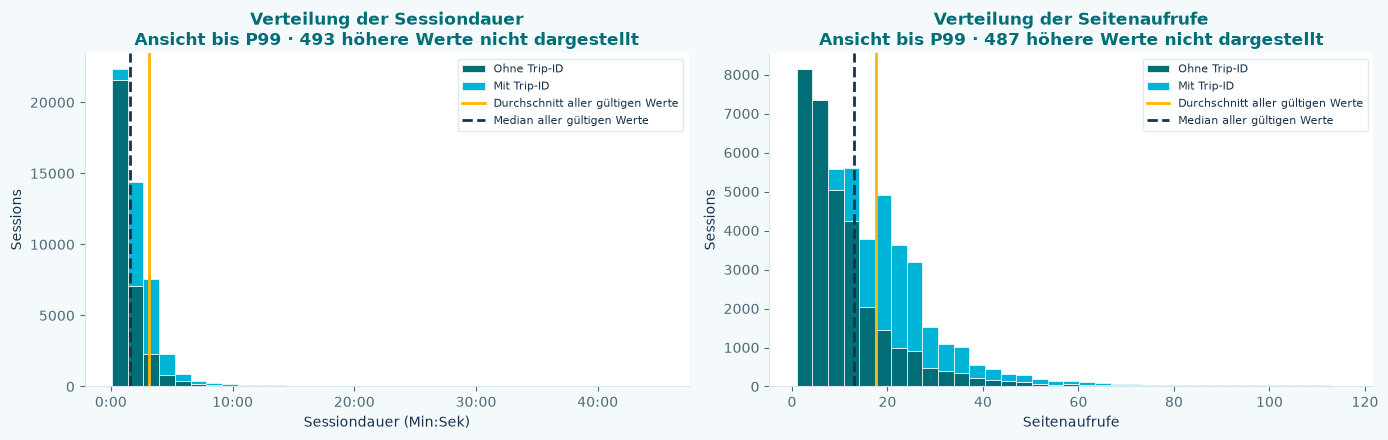

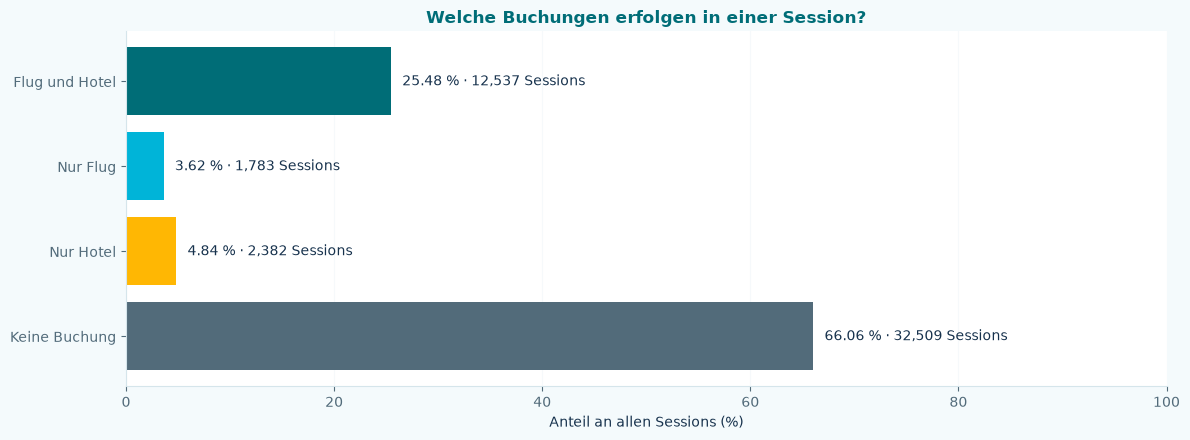

In [27]:
s = sessions_analysis

primary = THEME["primary"]
secondary = THEME["secondary"]

# Dauern auf der Achse als Minuten:Sekunden anzeigen
duration_formatter = FuncFormatter(
    lambda value, position: format_duration(value)
)




# --------------------------------------------------
# 1. Verteilung von Sessiondauer und Seitenaufrufen
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

has_trip = s["has_trip"]

for ax, column, title, xlabel, is_duration in [
    (
        axes[0],
        "valid_duration_min",
        "Verteilung der Sessiondauer",
        "Sessiondauer (Min:Sek)",
        True,
    ),
    (
        axes[1],
        "page_clicks",
        "Verteilung der Seitenaufrufe",
        "Seitenaufrufe",
        False,
    ),
]:
    values = sessions_analysis[column].dropna()

    if values.empty:
        ax.set_title(title)
        ax.text(
            0.5, 0.5, "Keine gültigen Werte",
            transform=ax.transAxes, ha="center",
        )
        continue

    # Gemeinsame Grenze und Klassen für beide Gruppen
    cutoff = values.quantile(0.99)
    visible = sessions_analysis[column].le(cutoff)
    hidden = int((values > cutoff).sum())

    groups = [
        sessions_analysis.loc[
            visible & ~has_trip, column
        ].dropna(),
        sessions_analysis.loc[
            visible & has_trip, column
        ].dropna(),
    ]

    ax.hist(
        groups,
        bins=35,
        stacked=True,
        color=[THEME["primary"], THEME["secondary"]],
        label=["Ohne Trip-ID", "Mit Trip-ID"],
        edgecolor=THEME["surface"],
        linewidth=0.5,
    )

    ax.axvline(
        values.mean(),
        color=THEME["accent"],
        linewidth=2,
        label="Durchschnitt aller gültigen Werte",
    )
    ax.axvline(
        values.median(),
        color=THEME["text"],
        linestyle="--",
        linewidth=2,
        label="Median aller gültigen Werte",
    )

    ax.set_title(
        f"{title}\n"
        f"Ansicht bis P99 · {hidden:,} höhere Werte nicht dargestellt"
    )
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Sessions")
    ax.legend(fontsize=8)

    if is_duration:
        ax.xaxis.set_major_formatter(duration_formatter)

finish_plot(fig)


# --------------------------------------------------
# 2. Buchungstypen: Anteile und Anzahl
# --------------------------------------------------
counts = s["booking_type"].value_counts().reindex(booking_order, fill_value=0)

# Kategorien ohne Sessions nicht als leere Balken darstellen
counts = counts[counts > 0]
shares = counts / len(s) * 100

colors = {
    "Flug und Hotel": primary,
    "Nur Flug": secondary,
    "Nur Hotel": THEME["accent"],
    "Keine Buchung": THEME["text_muted"],
    "Unbekannt": THEME["danger_border"],
}

fig, ax = plt.subplots(figsize=(12, 4.5))

bars = ax.barh(
    shares.index,
    shares.values,
    color=[colors[name] for name in shares.index],
)

ax.bar_label(
    bars,
    labels=[
        f"{share:.2f} % · {count:,} Sessions"
        for share, count in zip(shares, counts)
    ],
    padding=8,
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Anteil an allen Sessions (%)")
ax.set_title("Welche Buchungen erfolgen in einer Session?")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

finish_plot(fig)

### 6.2. Rabatte und Buchungsverhalten

In [ ]:
s = sessions_analysis

discount_reports = {}
discount_quality = []

show_note(
    "Verglichen werden Sessions mit und ohne Rabattangebot. "
    "Die Buchungsquote bezieht sich auf Sessions mit bekanntem "
    "Buchungsmerkmal in der jeweiligen Gruppe. "
    "Ein Zusammenhang belegt keine Wirkung des Rabatts."
)

# --------------------------------------------------
# 1. Flug- und Hotelrabatte getrennt auswerten
# --------------------------------------------------
for kind, label in [
    ("flight", "Flug"),
    ("hotel", "Hotel"),
]:
    flag_column = f"{kind}_discount"
    amount_column = f"{kind}_discount_amount"
    booking_column = f"{kind}_booked"

    offered = s[flag_column]
    booked = s[booking_column]

    raw = pd.to_numeric(s[amount_column], errors="coerce")
    valid_amount = raw.between(0, 1)

    # Rabattanteil als Prozentwert: 0.10 → 10 %
    s[f"{kind}_discount_pct"] = raw.where(valid_amount) * 100

    # Temporäre Tabelle für diese Auswertung
    analysis = pd.DataFrame({
        "Rabattangebot": offered,
        "Buchung": booked,
        "Rabatt (%)": s[f"{kind}_discount_pct"],
    })

    report = (
        analysis.groupby("Rabattangebot", dropna=False)
        .agg(
            Sessions=("Buchung", "size"),
            Bekannte_Buchungsmerkmale=("Buchung", "count"),
            Buchungen=("Buchung", lambda values: int(values.sum())),
            Buchungsquote=("Buchung", lambda values: values.mean() * 100),
            Bekannte_Rabattwerte=("Rabatt (%)", "count"),
            Durchschnittlicher_Rabatt=("Rabatt (%)", "mean"),
        )
        .rename(columns={
            "Bekannte_Buchungsmerkmale": "Sessions mit bekanntem Buchungsmerkmal",
            "Buchungsquote": "Buchungsquote (%)",
            "Bekannte_Rabattwerte": "Gültige Rabattbeträge",
            "Durchschnittlicher_Rabatt": "Ø hinterlegter Rabatt (%)",
        })
    )

    report.index = [
        "Unbekannt"
        if pd.isna(value)
        else "Rabatt angeboten"
        if value
        else "Kein Rabatt angeboten"
        for value in report.index
    ]
    report.index.name = "Rabattgruppe"

    # Numerische Berichte für spätere Diagramme behalten
    discount_reports[kind] = report

    eda.display_table(
        report,
        title=f"{label}rabatte: Angebote und Buchungen",
        card_width=WIDTH,
        max_height=450,
    )

    # --------------------------------------------------
    # 2. Auffälligkeiten dokumentieren
    # --------------------------------------------------
    discount_quality.append({
        "Bereich": label,
        "Rabatt angeboten": int(offered.fillna(False).sum()),
        "Unbekanntes Angebotsmerkmal": int(offered.isna().sum()),
        "Angebot ohne gültigen Betrag": int(
            (offered.fillna(False) & ~valid_amount).sum()
        ),
        "Betrag ohne Rabattangebot": int(
            (offered.eq(False).fillna(False) & raw.notna()).sum()
        ),
        "Nicht numerischer Betrag": int(
            (s[amount_column].notna() & raw.isna()).sum()
        ),
        "Betrag außerhalb 0-1": int(
            (raw.notna() & ~valid_amount).sum()
        ),
    })


# --------------------------------------------------
# 3. Qualitätsprüfung anzeigen
# --------------------------------------------------
quality_report = pd.DataFrame(discount_quality).set_index("Bereich")

show_note(
    "Die durchschnittliche Rabatthöhe berücksichtigt nur vorhandene "
    "Beträge zwischen 0 und 1. Fehlende Beträge werden nicht als 0 gewertet. "
    "Die Qualitätsprüfungen können sich überschneiden.",
    warning=bool(
        quality_report.drop(columns="Rabatt angeboten")
        .gt(0).any().any()
    ),
)

eda.display_table(
    quality_report,
    title="Rabatte: Vollständigkeit und Plausibilität",
    card_width=WIDTH,
    max_height=450,
)

,Sessions,Sessions mit bekanntem Buchungsmerkmal,Buchungen,Buchungsquote (%),Gültige Rabattbeträge,Ø hinterlegter Rabatt (%)
Rabattgruppe,,,,,,
Kein Rabatt angeboten,40319,40319,11740,29.12,0,-
Rabatt angeboten,8892,8892,2580,29.01,8282,13.99


,Sessions,Sessions mit bekanntem Buchungsmerkmal,Buchungen,Buchungsquote (%),Gültige Rabattbeträge,Ø hinterlegter Rabatt (%)
Rabattgruppe,,,,,,
Kein Rabatt angeboten,42396,42396,12380,29.20,0,-
Rabatt angeboten,6815,6815,2539,37.26,6205,11.22


,Rabatt angeboten,Unbekanntes Angebotsmerkmal,Angebot ohne gültigen Betrag,Betrag ohne Rabattangebot,Nicht numerischer Betrag,Betrag außerhalb 0–1
Bereich,,,,,,
Flug,8892,0,610,0,0,0
Hotel,6815,0,610,0,0,0


,Buchungssessions ohne gültigen Zeitpunkt,Ausgewählte Reisen,Passender Preisdatensatz,Kein Preisdatensatz
Bereich,,,,
Flug,0,13710,13710,0
Hotel,0,14309,14309,0


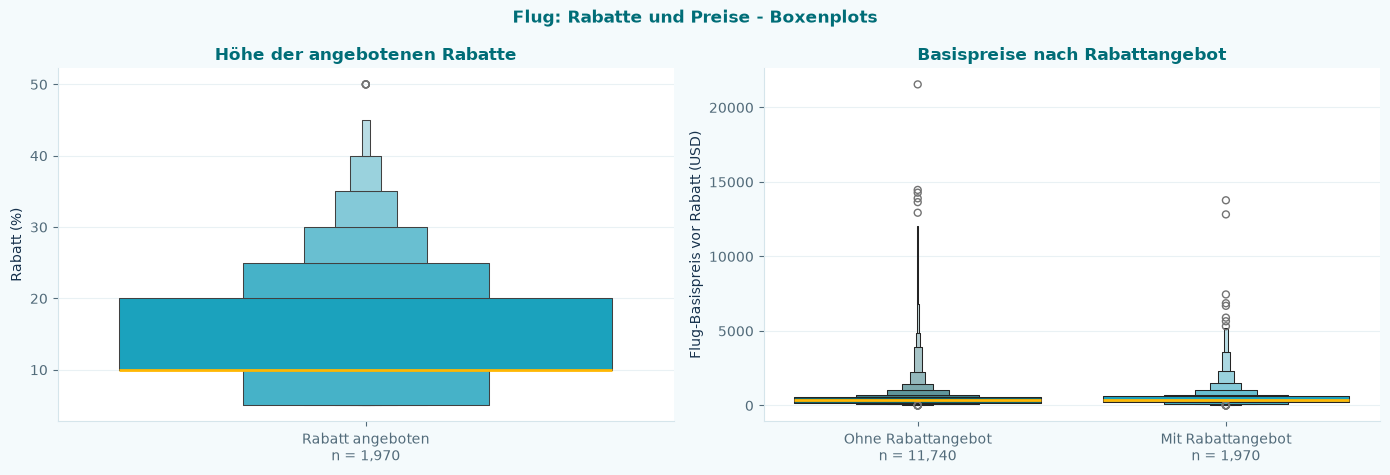

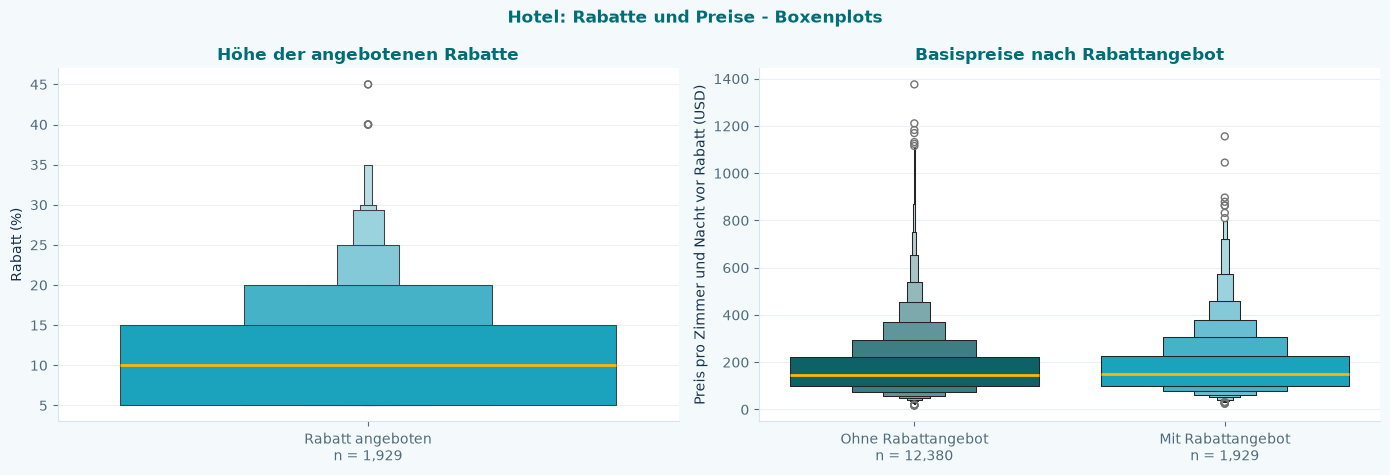

In [29]:
price_discount_data = {}
match_summary = []

for kind, frame, price_column, label in [
    ("flight", flights_analysis, "base_fare_usd", "Flug"),
    ("hotel", hotels_analysis, "hotel_per_room_usd", "Hotel"),
]:
    booked = sessions_analysis[f"{kind}_booked"]
    cancelled = sessions_analysis["cancellation"]

    bookings = sessions_analysis.loc[
        booked.fillna(False)
        & cancelled.eq(False).fillna(False)
        & sessions_analysis["trip_id"].notna()
    ].copy()

    bookings["booking_time"] = pd.to_datetime(
        bookings["session_start"],
        errors="coerce",
        utc=True,
        format="mixed",
    )

    missing_time = int(bookings["booking_time"].isna().sum())

    bookings = (
        bookings.dropna(subset=["booking_time"])
        .sort_values(["booking_time", "session_id"])
        .drop_duplicates("trip_id", keep="last")
    )

    bookings["discount_offered"] = bookings[f"{kind}_discount"]

    bookings["discount_pct"] = bookings[f"{kind}_discount_pct"]

    matched = bookings.merge(
        frame[["trip_id", price_column]],
        on="trip_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    price = pd.to_numeric(
        matched[price_column], errors="coerce"
    )

    matched["price_usd"] = price.where(
        np.isfinite(price) & price.ge(0)
    )

    match_summary.append({
        "Bereich": label,
        "Buchungssessions ohne gültigen Zeitpunkt": missing_time,
        "Ausgewählte Reisen": len(bookings),
        "Passender Preisdatensatz": int(
            matched["_merge"].eq("both").sum()
        ),
        "Kein Preisdatensatz": int(
            matched["_merge"].eq("left_only").sum()
        ),
    })

    # Gleiche Grundgesamtheit für Rabatt- und Preisdiagramme
    price_discount_data[kind] = matched.loc[
        matched["_merge"].eq("both")
    ].copy()

eda.display_table(
    pd.DataFrame(match_summary).set_index("Bereich"),
    title="Zuordnung der Buchungssessions zu Preisdatensätzen",
    card_width=WIDTH,
)

show_note(
    "Pro Reise wird die letzte beobachtete Buchungssession des jeweiligen "
    "Bereichs verwendet. Spätere Stornos schließen diese historische "
    "Buchung nicht aus. Verglichen werden Preise vor Rabatt."
)

# --------------------------------------------------
# 3. Diagramme für Flug und Hotel untereinander
# --------------------------------------------------

for kind, label, price_label in [
    ("flight", "Flug", "Flug-Basispreis vor Rabatt (USD)"),
    ("hotel", "Hotel", "Preis pro Zimmer und Nacht vor Rabatt (USD)"),
]:
    data = price_discount_data[kind].copy()

    data["Rabattgruppe"] = data["discount_offered"].map({
        False: "Ohne Rabattangebot",
        True: "Mit Rabattangebot",
    })

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # 1. Höhe der angebotenen Rabatte
    discounts = data.loc[
        data["discount_offered"].eq(True).fillna(False)
    ].dropna(subset=["discount_pct"])

    if not discounts.empty:
        sns.boxenplot(
            data=discounts,
            y="discount_pct",
            color=THEME["secondary"],
            line_kws={"color": THEME["accent"], "linewidth": 2},
            ax=axes[0],
        )
        axes[0].set_xticks(
            [0],
            [f"Rabatt angeboten\nn = {len(discounts):,}"],
        )
    else:
        axes[0].text(
            0.5, 0.5, "Keine gültigen Rabattwerte",
            transform=axes[0].transAxes, ha="center",
        )

    axes[0].set_title("Höhe der angebotenen Rabatte")
    axes[0].set_ylabel("Rabatt (%)")

    # 2. Preise mit und ohne Rabattangebot
    prices = data.dropna(subset=["Rabattgruppe", "price_usd"])
    order = ["Ohne Rabattangebot", "Mit Rabattangebot"]

    if not prices.empty:
        sns.boxenplot(
            data=prices,
            x="Rabattgruppe",
            y="price_usd",
            hue="Rabattgruppe",
            order=order,
            hue_order=order,
            palette={
                "Ohne Rabattangebot": THEME["primary"],
                "Mit Rabattangebot": THEME["secondary"],
            },
            legend=False,
            dodge=False,
            line_kws={"color": THEME["accent"], "linewidth": 2},
            ax=axes[1],
        )

        counts = prices["Rabattgruppe"].value_counts()
        axes[1].set_xticks(
            [0, 1],
            [
                f"{group}\nn = {counts.get(group, 0):,}"
                for group in order
            ],
        )
    else:
        axes[1].text(
            0.5, 0.5, "Keine gültigen Preise",
            transform=axes[1].transAxes, ha="center",
        )

    axes[1].set_title("Basispreise nach Rabattangebot")
    axes[1].set_xlabel("")
    axes[1].set_ylabel(price_label)

    for ax in axes:
        ax.set_facecolor(THEME["surface"])
        ax.grid(axis="y", color=THEME["border"], alpha=0.5)
        ax.set_axisbelow(True)
        ax.title.set_color(THEME["primary"])

    fig.patch.set_facecolor(THEME["background"])
    fig.suptitle(
        f"{label}: Rabatte und Preise - Boxenplots",
        color=THEME["primary"],
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

show_note(
    "Die gelbe Linie zeigt den Median. Die ineinanderliegenden Boxen zeigen "
    "weitere Quantilbereiche. Einzelne Randpunkte sind keine automatischen "
    "Datenfehler. Preisunterschiede können unter anderem durch Strecke, "
    "Sitzplatzanzahl oder Hotelwahl entstehen; sie belegen keinen Rabatteffekt."
)

### 6.3. Beobachtete Stornos und Sessiondauer nach Buchung
Die Stornoquote bezieht sich auf unterschiedliche beobachtete gebuchte Reisen. Stornos ohne
beobachtete Buchung werden separat ausgewiesen. Sie ist keine finale Teilbuchungsbilanz.

,count,mean,median
any_booking,,,
False,32509,1.418602,0.983333
True,16702,6.434194,2.716667


,Beobachtete gebuchte Reisen,Mit Storno ab Buchungszeit,Beobachtete Stornoquote (%),Storno ohne beobachtete Buchung
0,16099,610,3.79,0


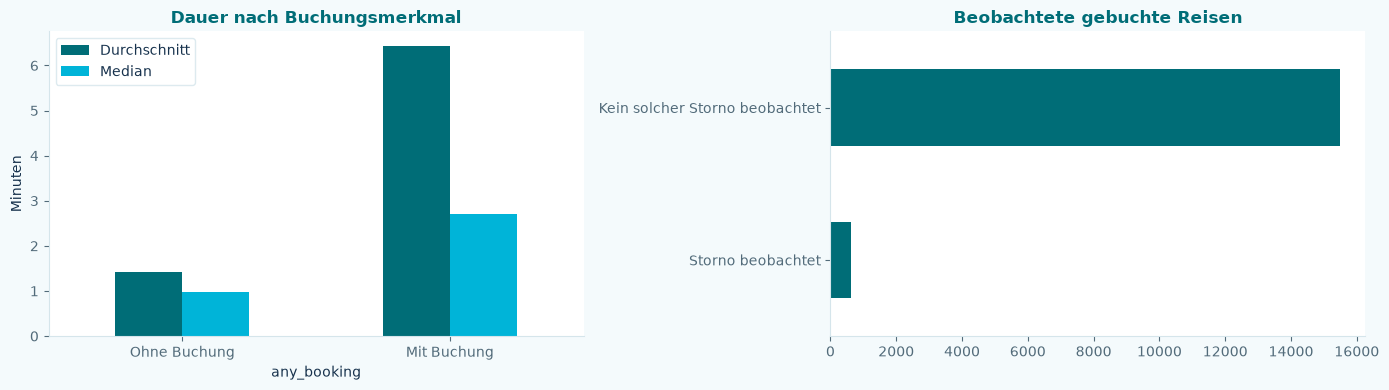

In [30]:
duration_by_booking = sessions_analysis.groupby("any_booking")["valid_duration_min"].agg(["count","mean","median"])
eda.display_table(duration_by_booking,title="Dauer in Minuten: mit und ohne Buchung",card_width=WIDTH)
booked_count = int(trip_activity["observed_booking"].sum())
cancel_count = int(trip_activity["cancellation_after_booking"].sum())
storno_report = pd.DataFrame([{"Beobachtete gebuchte Reisen":booked_count,"Mit Storno ab Buchungszeit":cancel_count,
    "Beobachtete Stornoquote (%)":100*cancel_count/booked_count if booked_count else np.nan,
    "Storno ohne beobachtete Buchung":int((trip_activity["observed_cancellation"] & ~trip_activity["observed_booking"]).sum())}])
eda.display_table(storno_report,title="Beobachtete reisebezogene Stornos",card_width=WIDTH)
fig,axes=plt.subplots(1,2,figsize=(14,4))
duration_by_booking[["mean","median"]].rename(columns={"mean":"Durchschnitt","median":"Median"}).plot.bar(ax=axes[0],rot=0)
axes[0].set_xticks(range(len(duration_by_booking)),["Mit Buchung" if v else "Ohne Buchung" for v in duration_by_booking.index]);axes[0].set_ylabel("Minuten");axes[0].set_title("Dauer nach Buchungsmerkmal")
pd.Series({"Storno beobachtet":cancel_count,"Kein solcher Storno beobachtet":booked_count-cancel_count}).plot.barh(ax=axes[1]);axes[1].set_title("Beobachtete gebuchte Reisen")
finish_plot(fig)

### 6.4. Flights - Reiseumfang und Basispreise
Der Preis je Sitzplatz verwendet die vorläufige Gesamtpreisinterpretation. Die Basispreise
sind vor Rabatt; Unterschiede können auch durch Strecke und Rückflugstatus entstehen.

,count,mean,std,min,25%,50%,75%,max
seats,13717.000000,1.200044,0.555145,1.000000,1.000000,1.000000,1.000000,8.000000
checked_bags,13717.000000,0.582562,0.657846,0.000000,0.000000,1.000000,1.000000,8.000000
bags_per_seat,13717.000000,0.513459,0.560948,0.000000,0.000000,0.500000,1.000000,5.000000
base_fare_usd,13717.000000,490.700007,701.362388,2.410000,198.530000,378.050000,591.080000,21548.040000
fare_per_seat_usd,13717.000000,389.350135,312.248797,2.410000,181.530000,350.510000,533.540000,3071.695000


,Anzahl,Anteil (%)
return_flight_booked,,
True,13120,95.65
False,597,4.35


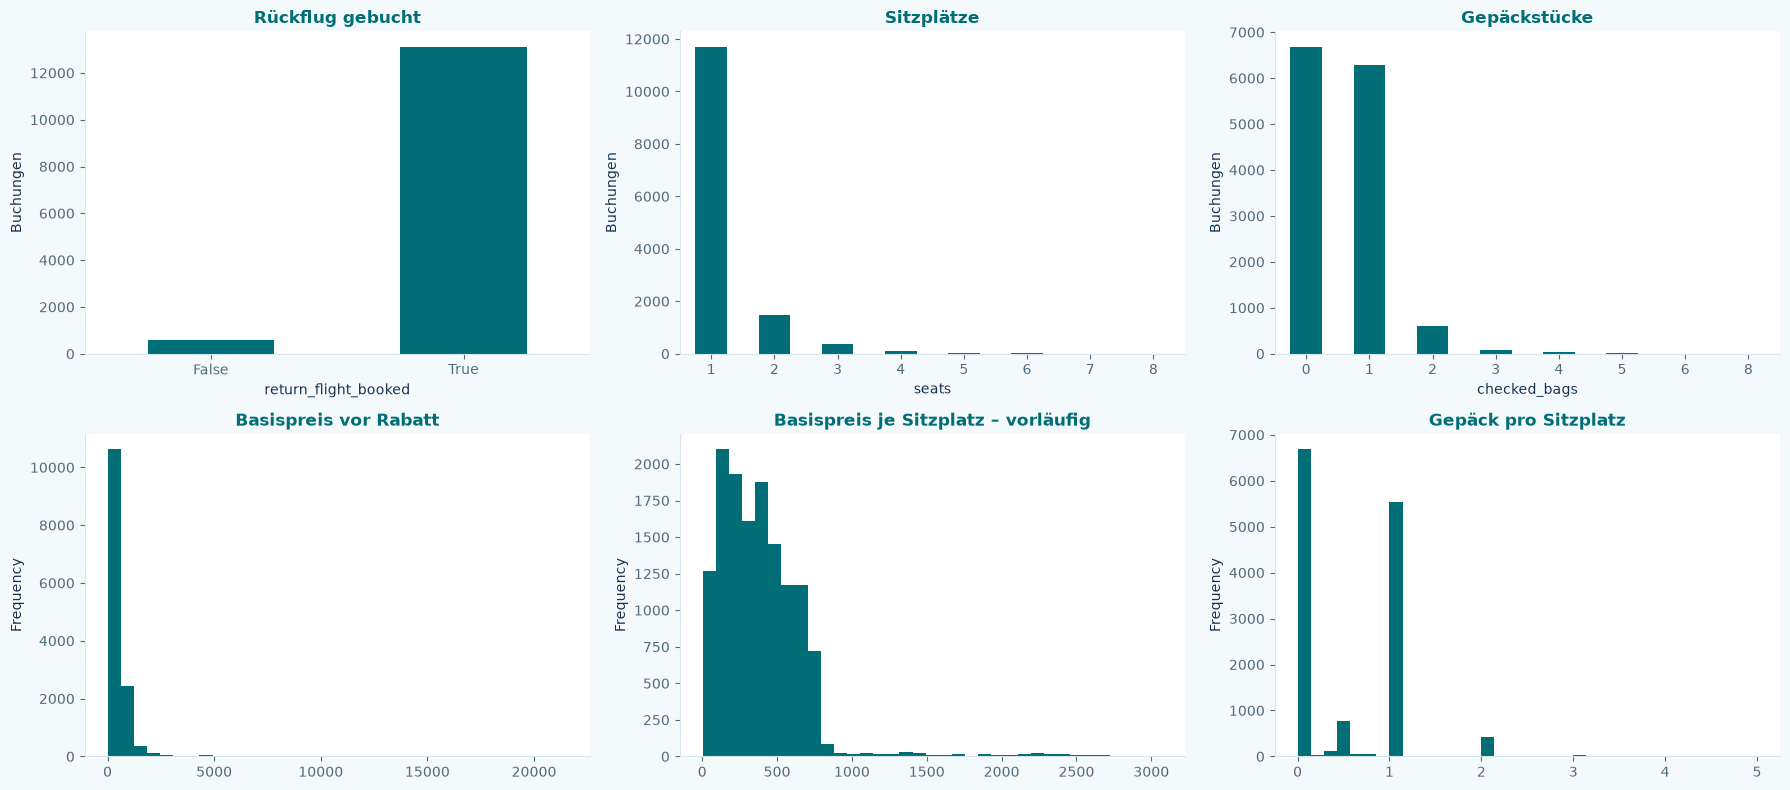

In [ ]:
flight_summary = numeric_summary(flights_analysis,["seats","checked_bags","bags_per_seat","base_fare_usd","fare_per_seat_usd"])
eda.display_table(flight_summary,title="Flights: numerische Kennzahlen",card_width=WIDTH)
eda.display_table(distribution(flights_analysis["return_flight_booked"]),title="Rückflug gebucht",card_width=WIDTH)
fig,axes=plt.subplots(2,3,figsize=(18,8))
for ax,column,title in [(axes[0,0],"return_flight_booked","Rückflug gebucht"),(axes[0,1],"seats","Sitzplätze"),(axes[0,2],"checked_bags","Gepäckstücke")]:
    flights_analysis[column].value_counts().sort_index().plot.bar(ax=ax,rot=0);ax.set_title(title);ax.set_ylabel("Buchungen")
for ax,column,title in [(axes[1,0],"base_fare_usd","Basispreis vor Rabatt"),(axes[1,1],"fare_per_seat_usd","Basispreis je Sitzplatz - vorläufig"),(axes[1,2],"bags_per_seat","Gepäck pro Sitzplatz")]:
    flights_analysis[column].dropna().plot.hist(bins=35,ax=ax);ax.set_title(title)
finish_plot(fig)

### 6.5. Users - Demografie und beobachtete Aktivität
Altersgruppen sind analytische Einteilungen. Reiseanzahlen beziehen sich auf die geladene
Historie und enthalten auch zukünftige oder später stornierte Buchungen.

,Anzahl,Anteil (%)
gender,,
F,5292,88.23
M,695,11.59
O,11,0.18


,Anzahl,Anteil (%)
married,,
False,3356,55.95
True,2642,44.05


,Anzahl,Anteil (%)
has_children,,
False,4040,67.36
True,1958,32.64


,count,mean,std,min,25%,50%,75%,max
age_years,5998.000000,40.877459,12.044377,16.000000,34.000000,41.000000,48.000000,88.000000
customer_tenure_days,5998.000000,188.898466,35.360982,71.000000,173.000000,190.000000,201.000000,736.000000
total_trips,5998.000000,2.684061,1.521032,0.000000,2.000000,3.000000,4.000000,8.000000


,users,mean_trips,median_trips
age_group,,,
Unter 18,246,1.113821,1.000000
18-20,147,1.102041,1.000000
21-24,256,1.144531,1.000000
25-34,937,2.401281,2.000000
35-44,2141,3.204110,3.000000
45-54,1656,3.106884,3.000000
55-64,382,2.329843,2.000000
65+,233,0.965665,1.000000


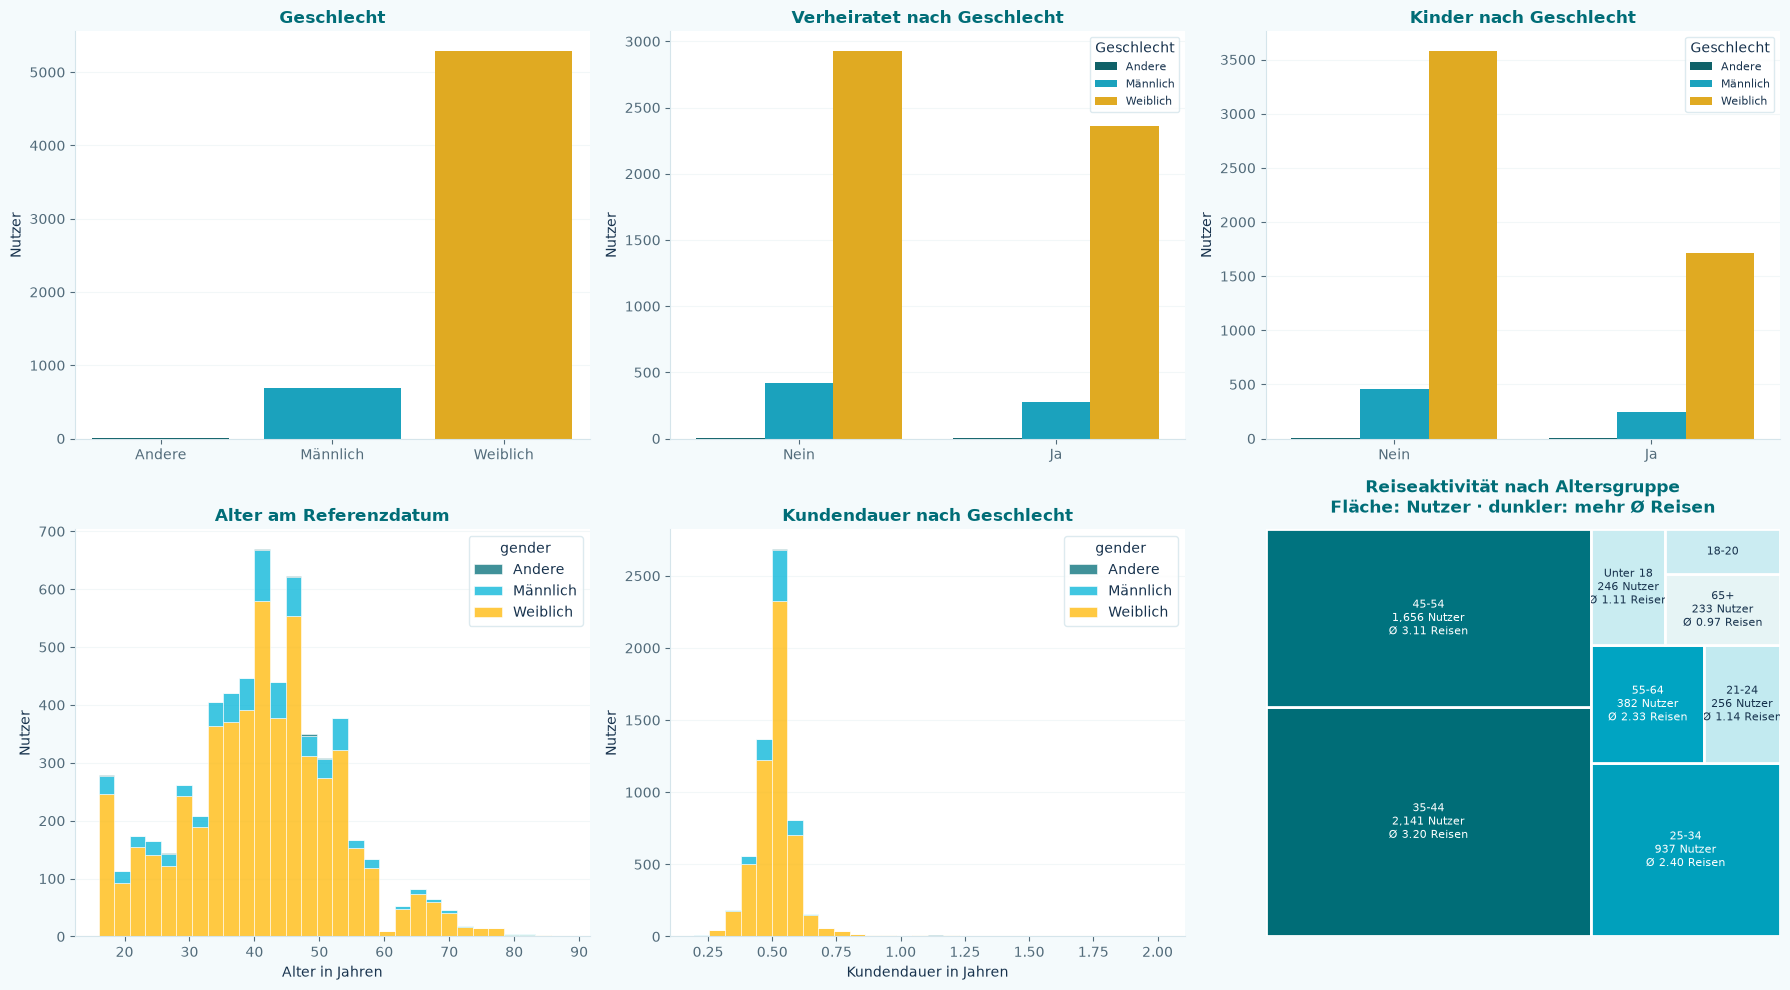

In [32]:
# --------------------------------------------------
# 1. Tabellen
# --------------------------------------------------
for column, title in [
    ("gender", "Geschlecht"),
    ("married", "Familienstand"),
    ("has_children", "Kinder"),
]:
    eda.display_table(
        distribution(users_analysis[column]),
        title=f"Users: {title}",
        card_width=WIDTH,
    )

eda.display_table(
    numeric_summary(
        users_analysis,
        ["age_years", "customer_tenure_days", "total_trips"],
    ),
    title="Alter, Kundendauer und Reisen",
    card_width=WIDTH,
)

age_activity = (
    users_analysis.groupby("age_group", observed=False)
    .agg(
        users=("user_id", "size"),
        mean_trips=("total_trips", "mean"),
        median_trips=("total_trips", "median"),
    )
)

eda.display_table(
    age_activity,
    title="Aktivität nach Altersgruppen",
    card_width=WIDTH,
)


# --------------------------------------------------
# 2. Anzeigedaten und Farben vorbereiten
# --------------------------------------------------
users_plot = users_analysis.copy()

users_plot["gender"] = (
    users_plot["gender"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "": "Unbekannt",
        "f": "Weiblich",
        "m": "Männlich",
        "o": "Andere",
        "female": "Weiblich",
        "male": "Männlich",
        "other": "Andere",
    })
    .fillna("Unbekannt")
)

for column in ["married", "has_children"]:
    users_plot[column] = (
        as_bool(users_plot[column])
        .map({False: "Nein", True: "Ja"})
        .astype("string")
        .fillna("Unbekannt")
    )

users_plot["customer_tenure_years"] = (
    users_plot["customer_tenure_days"] / 365.25
)

gender_order = sorted(users_plot["gender"].unique())

gender_colors = [
    THEME["primary"],
    THEME["secondary"],
    THEME["accent"],
    THEME["text_muted"],
]

gender_palette = {
    gender: gender_colors[i % len(gender_colors)]
    for i, gender in enumerate(gender_order)
}


# --------------------------------------------------
# 3. Abbildung erstellen
# --------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Geschlechterverteilung
sns.countplot(
    data=users_plot,
    x="gender",
    hue="gender",
    order=gender_order,
    hue_order=gender_order,
    palette=gender_palette,
    legend=False,
    ax=axes[0, 0],
)

axes[0, 0].set_title("Geschlecht")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Nutzer")


# Familienstand und Kinder nach Geschlecht
for ax, column, title in [
    (axes[0, 1], "married", "Verheiratet nach Geschlecht"),
    (axes[0, 2], "has_children", "Kinder nach Geschlecht"),
]:
    category_order = [
        value
        for value in ["Nein", "Ja", "Unbekannt"]
        if value in users_plot[column].unique()
    ]

    sns.countplot(
        data=users_plot,
        x=column,
        hue="gender",
        order=category_order,
        hue_order=gender_order,
        palette=gender_palette,
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Nutzer")
    ax.legend(title="Geschlecht", fontsize=8)


# Alter und Kundendauer: nach Geschlecht gestapelt
for ax, column, title, xlabel in [
    (
        axes[1, 0],
        "age_years",
        "Alter am Referenzdatum",
        "Alter in Jahren",
    ),
    (
        axes[1, 1],
        "customer_tenure_years",
        "Kundendauer nach Geschlecht",
        "Kundendauer in Jahren",
    ),
]:
    plot_data = users_plot.loc[
        np.isfinite(users_plot[column])
    ]

    if not plot_data.empty:
        sns.histplot(
            data=plot_data,
            x=column,
            hue="gender",
            hue_order=gender_order,
            palette=gender_palette,
            bins=30,
            multiple="stack",
            common_bins=True,
            edgecolor=THEME["surface"],
            linewidth=0.4,
            ax=ax,
        )
    else:
        ax.text(
            0.5, 0.5,
            "Keine gültigen Werte",
            transform=ax.transAxes,
            ha="center",
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Nutzer")


# --------------------------------------------------
# 4. Treemap: Altersgruppen und Reiseaktivität
# Fläche = Nutzerzahl, Farbe = durchschnittliche Reisen
# --------------------------------------------------
treemap_ax = axes[1, 2]

data = (
    age_activity.loc[
        age_activity["users"].gt(0),
        ["users", "mean_trips"],
    ]
    .sort_values("users", ascending=False)
)

color_map = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "traveltide",
    [
        THEME["surface_alt"],
        THEME["secondary"],
        THEME["primary"],
    ],
)

valid_means = data["mean_trips"].dropna()

minimum = valid_means.min() if not valid_means.empty else 0
maximum = valid_means.max() if not valid_means.empty else 1

norm = plt.Normalize(
    vmin=minimum,
    vmax=maximum if maximum > minimum else minimum + 1,
)




treemap_ax.set_xlim(0, 1)
treemap_ax.set_ylim(0, 1)
treemap_ax.set_aspect("auto")
treemap_ax.margins(0)
treemap_ax.axis("off")

treemap_ax.set_title(
    "Reiseaktivität nach Altersgruppe\n"
    "Fläche: Nutzer · dunkler: mehr Ø Reisen",
    pad=12,
)


# --------------------------------------------------
# 5. Theme und Layout
# --------------------------------------------------
for ax in axes.flat:
    ax.set_facecolor(THEME["surface"])
    ax.title.set_color(THEME["primary"])

    if ax is not treemap_ax:
        ax.grid(
            axis="y",
            color=THEME["border"],
            alpha=0.3,
        )
        ax.set_axisbelow(True)

fig.patch.set_facecolor(THEME["background"])

# Erst Layout festlegen, anschließend Treemap zeichnen
fig.tight_layout()
fig.canvas.draw()

draw_treemap(data, 0, 0, 1, 1)

plt.show()

### 6.6. Hotels - Nächte, Zimmer und Kosten
Widersprüchliche Aufenthalte sind aus Dauer- und Gesamtkostenkennzahlen ausgeschlossen.
Andere Abweichungen der Nachtangaben werden zusätzlich sichtbar gehalten; strengere Kosten
verwenden nur mit dem Kalendervergleich übereinstimmende Fälle. Preise sind vor Rabatt.

,count,mean,std,min,25%,50%,75%,max
valid_nights,14087.000000,3.683893,3.748551,0.000000,1.000000,3.000000,5.000000,43.000000
valid_rooms,14313.000000,1.194369,0.498269,1.000000,1.000000,1.000000,1.000000,4.000000
valid_hotel_per_room_usd,14313.000000,178.046112,118.567176,17.000000,99.000000,148.000000,223.000000,1376.000000
hotel_total_before_discount_usd,14087.000000,796.516576,1256.686367,0.000000,181.000000,412.000000,912.000000,27702.000000
hotel_total_strict_usd,5544.000000,1136.802128,1650.592408,0.000000,264.000000,616.000000,1350.000000,27702.000000


,Anzahl,Anteil (%)
nights_check,,
Abweichende Nachtangabe,8543,59.69
Übereinstimmung,5544,38.73
Nicht prüfbar / ungültig,226,1.58


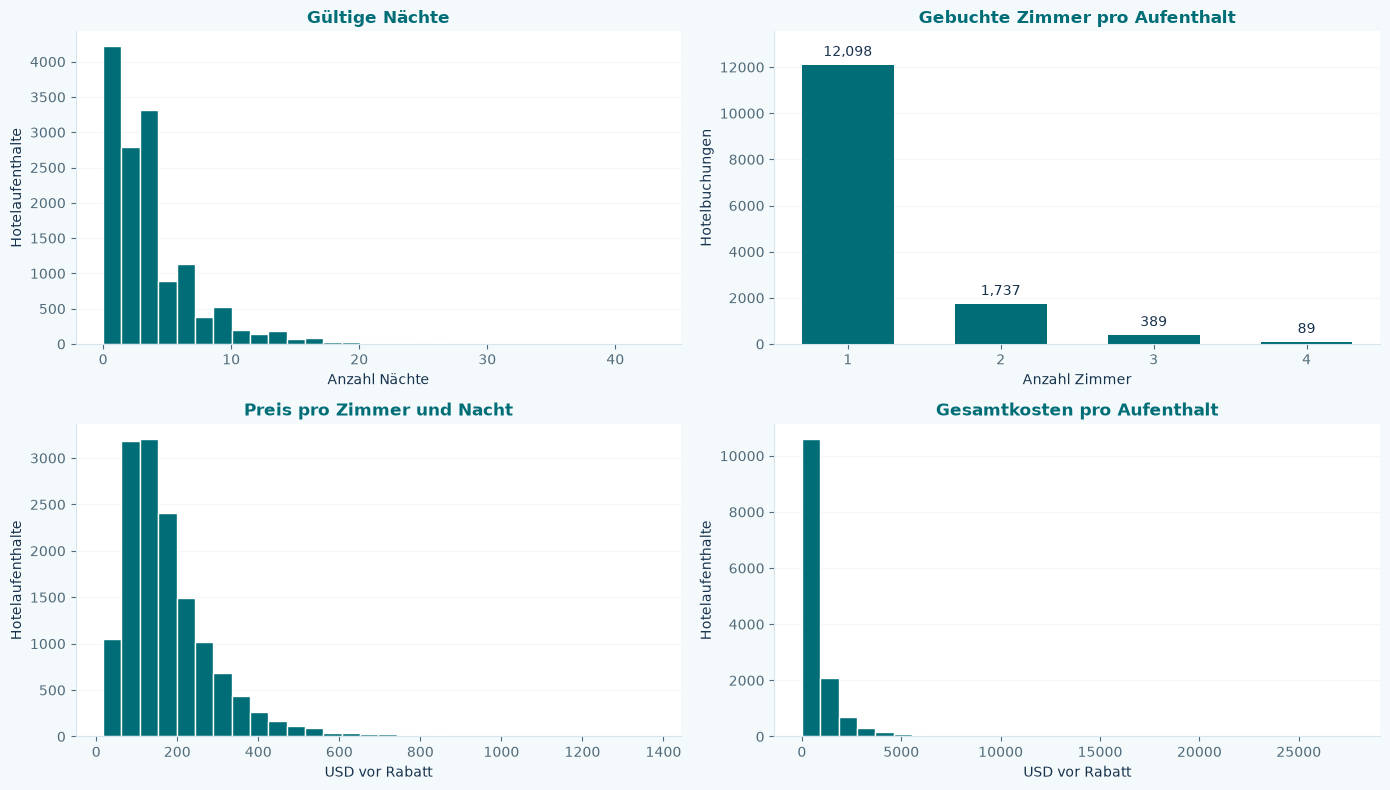

In [33]:
# --------------------------------------------------
# 1. Kennzahlen
# --------------------------------------------------
eda.display_table(
    numeric_summary(
        hotels_analysis,
        [
            "valid_nights",
            "valid_rooms",
            "valid_hotel_per_room_usd",
            "hotel_total_before_discount_usd",
            "hotel_total_strict_usd",
        ],
    ),
    title="Hotels: Kennzahlen",
    card_width=WIDTH,
)

eda.display_table(
    distribution(hotels_analysis["nights_check"]),
    title="Nächteprüfung",
    card_width=WIDTH,
)

# --------------------------------------------------
# 2. Diagramme
# --------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Nächte und Preise als Histogramme
for ax, column, title, xlabel in [
    (
        axes[0, 0],
        "valid_nights",
        "Gültige Nächte",
        "Anzahl Nächte",
    ),
    (
        axes[1, 0],
        "valid_hotel_per_room_usd",
        "Preis pro Zimmer und Nacht",
        "USD vor Rabatt",
    ),
    (
        axes[1, 1],
        "hotel_total_before_discount_usd",
        "Gesamtkosten pro Aufenthalt",
        "USD vor Rabatt",
    ),
]:
    hotels_analysis[column].dropna().plot.hist(
        bins=30,
        ax=ax,
        color=THEME["primary"],
        edgecolor=THEME["surface"],
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Hotelaufenthalte")

# Zimmeranzahl separat als Balkendiagramm
ax = axes[0, 1]

room_counts = (
    hotels_analysis["valid_rooms"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

bars = ax.bar(
    room_counts.index,
    room_counts.values,
    color=THEME["primary"],
    width=0.6,
)

ax.set_xticks(room_counts.index)
ax.set_xlabel("Anzahl Zimmer")
ax.set_ylabel("Hotelbuchungen")
ax.set_title("Gebuchte Zimmer pro Aufenthalt")

ax.bar_label(
    bars,
    labels=[f"{count:,}" for count in room_counts.values],
    padding=4,
)

ax.margins(y=0.12)

# Gemeinsame Gestaltung
for ax in axes.flat:
    ax.grid(axis="y", color=THEME["border"], alpha=0.3)
    ax.set_axisbelow(True)

finish_plot(fig)

### 6.7. Week-1-Abschluss und Übergabe
Die Exploration, Anomalieprüfung und Kohortenauswahl münden in `session_dataset` mit einer
Zeile pro Session. Schlüssel bleiben für Nachvollziehbarkeit erhalten; überflüssige rechte
Schlüsselkopien werden durch die Joins nicht erzeugt. Die ID-Präfixe sind kein zusätzlicher
Modellierungsmerkmalsvorschlag. Exportierte CSVs speichern die Datentypen nicht mit.

Annahmen: Flug-Gesamtpreis vorläufig; Hotelpreis pro Zimmer und Nacht dokumentiert;
Stornoquote beobachtungsbezogen. Kein Hotelaufenthalt wird pauschal über Flugzeiten korrigiert.
Vor Week 2 die wichtigsten Erkenntnisse aus Abschnitt 6 kurz zusammenfassen.
Die Exportzelle zuletzt ausführen, damit auch die ergänzten Rabattanalyse-Spalten enthalten sind.

In [34]:
# Aktuelle Sessionmerkmale übernehmen
assert session_dataset["session_id"].equals(
    sessions_analysis["session_id"]
)

for column in sessions_analysis.columns:
    session_dataset[column] = sessions_analysis[column].to_numpy()

assert len(session_dataset) == len(df_sessions)
assert session_dataset["session_id"].is_unique

RUN_PREPROCESSING_EXPORT = False
if RUN_PREPROCESSING_EXPORT:
    # Zielordner aus der gespeicherten Konfiguration laden
    importlib.reload(config)
    
    output_folder = config.DATA_PREPROCESSING_FOLDER
    output_folder.mkdir(parents=True, exist_ok=True)
    
    # Alle fünf Datensätze exportieren
    exports = {
        "session_level_analysis": session_dataset,
        "sessions_analysis": sessions_analysis,
        "flights_analysis": flights_analysis,
        "users_analysis": users_analysis,
        "hotels_analysis": hotels_analysis,
    }
    
    for name, frame in exports.items():
        output_path = output_folder / f"{name}.csv"
    
        frame.to_csv(output_path, index=False)
    
        show_note(
            f"✓ {name}: {len(frame):,} Zeilen · "
            f"{frame.shape[1]} Spalten · {output_path}"
        )
else:
    show_note("Aufbereitung geprüft; vorhandene Analyse-CSVs nicht überschrieben. Für einen bewussten Neuaufbau RUN_PREPROCESSING_EXPORT=True setzen.")


## 7. Zusammenfassung der Exploration
- Der Session-Datensatz behält eine Zeile je Session; Joins dürfen Buchungen nicht vervielfachen.
- Widersprüchliche Hotelaufenthalte bleiben in Buchungszählungen, liefern aber keine gültigen Dauer-/Gesamtkostenwerte.
- Flug-Basispreise werden vorläufig als Gesamtpreis vor Rabatt interpretiert; Hotelpreise gelten pro Zimmer und Nacht.
- Der ungefilterte Bestand enthält ab 21.07.2023 ausschließlich Buchungssessions. Notebook 03 dokumentiert diesen Datenbruch.
- Der Abschluss verwendet den 16.07.2023 als Stichtag und behält für den Vergleich die ursprüngliche Nutzerkohorte.